# Curvature review: original implementations versus current code

The intrinsic baseline below is **the exact original `curvature.py` attachment**, SHA-256 `241a883882d17cab3cc135445c496940de4eb6082086ebd609409a65dc8ae840`. It matches initial commit `eb2e884`; its matching derivative, patch and cyclic helpers are embedded too. This baseline includes the original flatten-and-stack patch implementation. The attachment predates extrinsic curvature, so extrinsic uses the separately frozen pre-fix implementation from `99cf6c9`. Both frozen closures execute with isolated imports and SHA-256 checks; neither calls current numerical helpers.

Current intrinsic/extrinsic code is imported from the working checkout, including the intrinsic conditioning fast path and metric-first tiling. Restart the kernel after editing library code. Both versions receive identical points, dtype, spacings, periodic axes, patch sizes and device. We report numerical differences, analytic errors where available, failures and median elapsed runtime. Intentional correctness fixes need not reproduce incorrect original outputs. Image curvature has no ground truth here.

**CUDA is the default.** Set `DEVICE="cpu"` explicitly for CPU checks. CUDA timing is synchronized. Preparation, hashing and comparisons are excluded from curvature timings; each version gets an untimed warm-up and `REPEATS` timed calls. Old/new call order alternates across cases.

`PROFILE="bounded"` covers every mathematical family/ambient variant and image class at two reduced grids, retaining full intrinsic dimension and all 4096 pixels. These runs check behavior, not convergence of full image manifolds. `PROFILE="original"` restores the ten-size mathematical schedules and original image parents/subgrids; `INCLUDE_FULL_DSPRITES` controls its last dSprites run. The original intrinsic baseline materializes all overlapping image patches and can require substantially more host RAM at those resolutions.

The code cell immediately after the final plot prints a **copyable Markdown run report** from the actual result rows, run metadata/configuration and current date-time. Paste its plain-text output into a Markdown cell. The final static CPU report is explicitly historical and belongs to an earlier comparison.


In [3]:
from pathlib import Path
from time import perf_counter
from statistics import median
from datetime import datetime
from zoneinfo import ZoneInfo
import builtins
import csv
import hashlib
import json
import platform
import subprocess
import sys
import types

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

PACKAGE_ROOT = next(candidate for p in (Path.cwd(), *Path.cwd().parents)
                    for candidate in (p, p / "manifold-microscope")
                    if (candidate / "microscope/computations_grid/curvature.py").is_file())
sys.path.insert(0, str(PACKAGE_ROOT))

from microscope.computations_grid import curvature as fixed_intrinsic
from microscope.computations_grid import curvature_extrinsic as fixed_extrinsic
from microscope.datasets import custom_dsprites, coil20
from microscope.manifold_examples.ellipsoid import ellipsoid_scalar_curvature
from microscope.manifold_examples.hyperboloid import hyperboloid_scalar_curvature
from microscope.manifold_examples.sphere import sphere_scalar_curvature
from microscope.manifold_examples.sampling_grid import sample_ellipsoid_on_grid, sample_hyperboloid_on_grid
from microscope.cyclic_dimensions import get_difference_intervals

PROFILE = "bounded"  # "bounded" or "original"
DEVICE = "cuda:0"  # Set explicitly to "cpu" for a CPU comparison.
DTYPE = np.float32
REPEATS = 2
CPU_THREADS = 2
INCLUDE_FULL_DSPRITES = True  # Applies to original-profile image grids.
N_SIZES = 10
SEED = 0
APPLY_RANDOM_ISOMETRY = False
INCLUDE_TOTAL_TEST_GRID = True
INCLUDE_SLOW_TESTS = True
SLOW_CASE_NAMES = None

assert PROFILE in ("bounded", "original")
assert REPEATS >= 1
if str(DEVICE).startswith("cuda") and not torch.cuda.is_available():
    raise RuntimeError("Requested CUDA is unavailable; select CPU explicitly.")
torch.set_num_threads(CPU_THREADS)
np.random.seed(SEED)
REPORT_TIMEZONE = "Europe/Berlin"
RUN_STARTED_AT = datetime.now(ZoneInfo(REPORT_TIMEZONE))
RUN_ID = RUN_STARTED_AT.strftime("%Y%m%dT%H%M%S_%f%z")
OUTPUT_DIR = PACKAGE_ROOT.parent / "outputs/CURVATURE_REVIEW" / RUN_ID / PROFILE
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
ORIGINAL_INTRINSIC_SOURCES = {}
ORIGINAL_INTRINSIC_HASHES = {}
PREVIOUS_SOURCES = {}
PREVIOUS_HASHES = {}


## Original intrinsic implementation and its matching helpers

Verbatim attachment and dependency closure from initial commit `eb2e884`. These sources run independently of the extrinsic baseline below.

### Original intrinsic source: `microscope/cyclic_dimensions.py`

SHA-256: `ddda3c6ce4608a46eb69c8f0eaadde142d2865ea0b8ab39f63338ed451e36407`.

In [4]:
ORIGINAL_INTRINSIC_SOURCES['microscope.cyclic_dimensions'] = r'''import numpy as np


def pad_cyclic_dimensions(
        array: np.ndarray,
        cyclic_dimensions: list[int],
        pad_sizes: list[int]
) -> np.ndarray:
    """Pad an array on both sides along cyclic dimensions in a circular way.

    Args:
        array: The array to pad.
        cyclic_dimensions: The dimensions along which to pad.
        pad_sizes: The size of the padding per cyclic dimension. It will be applied on both sides,
            i.e. the array will grow by 2*pad_size.

    Returns:
        The padded array.
    """
    if len(cyclic_dimensions) != len(pad_sizes):
        raise ValueError(
            f"Expected the number of cyclic dimensions ({len(cyclic_dimensions)}) to equal the number"
            f"of pad sizes ({len(pad_sizes)})."
        )
    for dim, pad_size in zip(cyclic_dimensions, pad_sizes):
        pad_front = array.take(indices=range(-pad_size, 0), axis=dim)
        pad_back = array.take(indices=range(pad_size), axis=dim)
        array = np.concatenate([pad_front, array, pad_back], axis=dim)

    return array


def get_difference_intervals(
        n_samples_per_dim: list[int],
        range_sizes: list[float],
        cyclic_dimensions: list[int]
) -> list[float]:
    """Computes the finite difference corresponding to the different dimensions. The difference is constant for all
    intervals and computed by dividing the range size with the number of samples if the dimension is cyclic else the
    number of samples minus 1.

    Args:
        n_samples_per_dim: The number of samples per dimension of the data.
        range_sizes: The value ranges along each dimension.
        cyclic_dimensions: An array of booleans indicating which dimensions are cyclic.

    Returns:
        A list with the difference interval per dimension.
    """
    return [
        size / n_samples
        if dim in cyclic_dimensions
        else size / (n_samples - 1)

        for dim, [size, n_samples]
        in enumerate(zip(range_sizes, n_samples_per_dim))
    ]
'''
ORIGINAL_INTRINSIC_HASHES['microscope.cyclic_dimensions'] = 'ddda3c6ce4608a46eb69c8f0eaadde142d2865ea0b8ab39f63338ed451e36407'

### Original intrinsic source: `microscope/patches.py`

SHA-256: `ed2a489bacf0c4880ba988babe874aeaba3f23110d0c31ed4bde631440ace120`.

In [5]:
ORIGINAL_INTRINSIC_SOURCES['microscope.patches'] = r'''from typing import Optional

import numpy as np
from einops import einops

from microscope.cyclic_dimensions import pad_cyclic_dimensions


def extract_patches(
        array: np.ndarray,
        patch_sizes: list[int],
        overlaps: list[int],
        cyclic_dimensions: Optional[list[int]] = None,
        verbose: bool = False
) -> np.ndarray:
    """
    Generalized function to extract overlapping patches from the first n - d dimensions of a multidimensional array,
    leaving the last d dimensions untouched. If size of the array is not divisible by the resulting step size
    along all spacial dimensions, it will be 0-padded to the next size that is divisible. This means that the caller
    is responsible to truncate outputs on a later stage to compensate for those artificial padded values.

    Args:
        array: The input array to split.
        patch_sizes: The size of each patch along the first n - d dimensions.
        overlaps: The overlap along each of the first n - d dimensions.
        cyclic_dimensions: A set of dimensions where the grid is cyclic.
        verbose: If true it prints info and warning messages.


    Returns:
        A view of the overlapping patches, preserving their structure.
    """
    if cyclic_dimensions is None:
        cyclic_dimensions = []

    n_dim = len(patch_sizes)
    n_features = len(array.shape) - n_dim

    if len(overlaps) != n_dim:
        raise ValueError(
            f"The shape dimensions of the patch sizes ({n_dim}) differ from the "
            f"shape dimensions of the overlaps ({len(overlaps)})."
        )
    # Handle cyclic dimensions by padding the array
    array = pad_cyclic_dimensions(
        array,
        cyclic_dimensions=cyclic_dimensions,
        pad_sizes=[overlaps[dim] // 2 for dim in cyclic_dimensions]
    )

    patch_sizes = np.array(patch_sizes)
    overlaps = np.array(overlaps)
    step_sizes = patch_sizes - overlaps

    array_shape = np.array(array.shape[:n_dim])
    feature_shape = array.shape[n_dim:]

    residue = array_shape - overlaps - (step_sizes * ((array_shape - overlaps) // step_sizes))
    # noinspection PyUnresolvedReferences
    if (residue != 0).any():
        array_old_shape = array_shape
        # noinspection PyTypeChecker
        array = np.pad(
            array,
            pad_width=
            tuple((0, r) for r in (step_sizes - residue))
            + tuple(((0, 0) for _ in range(n_features))),
            mode="wrap"
        )
        array_shape = np.array(array.shape[:n_dim])
        feature_shape = array.shape[n_dim:]

        if verbose:
            print(
                f"WARNING: Array shape minus patch size {array_shape - patch_sizes} is not divisible by the step size "
                f"{step_sizes} (patch_size - overlap) along all dimensions. Zero padding the array of size "
                f"({array_old_shape}) to ({array_shape}) to compensate for that."
            )

    # Compute new shape and strides for patches
    patch_shape = tuple((array_shape - overlaps) // step_sizes) + tuple(patch_sizes) + feature_shape
    strides = array.strides
    patch_strides = (
        tuple(
            stride * step
            for stride, step
            in zip(strides[:n_dim], step_sizes))
        + strides[:n_dim]
        + strides[n_dim:]
    )
    # Extract overlapping patches using as_strided
    patches = np.lib.stride_tricks.as_strided(array, shape=patch_shape, strides=patch_strides)

    return patches


def stack_patches(patches: np.ndarray, n_features: int) -> np.ndarray:
    """
    Reconstructs an array from non-overlapping patches using einops.

    Args:
        patches: The patches arranged in a grid, with shape (g1, g2, ... p1, p2 ... n_features).
        n_features: The number of features which are not patched.

    Returns:
        An array with all the patches stacked along their corresponding dimensions.
    """
    # Number of spatial dimensions.
    n_dim = (len(patches.shape) - n_features) // 2

    # Dynamically construct einops pattern
    grid_dims = [f"grid{i}" for i in range(n_dim)]
    patch_dims = [f"patch{i}" for i in range(n_dim)]
    zipped_dims = [f"({g} {p})" for g, p in zip(grid_dims, patch_dims)]
    einops_pattern = f"{' '.join(grid_dims)} {' '.join(patch_dims)} ... -> {' '.join(zipped_dims)} ..."

    # Rearrange patches to reconstruct the array
    array = einops.rearrange(patches, einops_pattern)

    return array
'''
ORIGINAL_INTRINSIC_HASHES['microscope.patches'] = 'ed2a489bacf0c4880ba988babe874aeaba3f23110d0c31ed4bde631440ace120'

### Original intrinsic source: `microscope/computations_grid/basic.py`

SHA-256: `2d89b03e44ed95594901ca5db0325449c9c078895a390fdd7bcc88692501658f`.

In [6]:
ORIGINAL_INTRINSIC_SOURCES['microscope.computations_grid.basic'] = r'''import numpy as np
import torch

from microscope.patches import extract_patches, stack_patches


def partial_derivative_approximation(
    tensor: torch.Tensor,
    dim: int,
    difference_intervals: float
) -> torch.Tensor:
    """Estimate the partial derivative of a tensor along a dimension and a given sample size, assuming the samples are
    equidistantly placed on a grid.

    Args:
        tensor: An input tensor of shape (s1 ... sk f1 ... fl).
        dim: The index of the dimension along which the partial derivative will be computed.
        difference_intervals: The h value for each dimension of the grid.

    Returns:
        A tensor of dimension (s1 ... si_ ... sk f1 ... fl) with the partial derivative along the i-th dimension.
    """
    device = tensor.device
    length = tensor.shape[dim]

    t_plus = torch.index_select(tensor, dim=dim, index=torch.arange(2, length, device=device))
    t_minus = torch.index_select(tensor, dim=dim, index=torch.arange(0, length - 2, device=device))

    return (t_plus - t_minus) / (2 * difference_intervals)


def crop_dim_borders(tensor: torch.Tensor, dims: set[int], crop: int = 1) -> torch.Tensor:
    """Crop the borders of a given set of dimensions by a given value. This can be used to ensure that tensors which
    have been cropped along different dimension during estimations can be further cropped to have the same shape.

    Args:
        tensor: The tensor to be cropped.
        dims: A set of dimensions to crop the tensor on.
        crop: A integer indicating the amount of cropping at the start and end of a dimension of the tensor.

    Returns:
        The cropped tensor.
    """
    device = tensor.device

    for d in dims:
        length = tensor.shape[d]
        tensor = torch.index_select(tensor, dim=d, index=torch.arange(crop, length - crop, device=device))

    return tensor


def partial_derivatives_across_all_dims(
    tensor: torch.Tensor,
    manifold_dim: int,
    difference_intervals: list[float]
) -> torch.Tensor:
    """Given a tensor of shape (s1 ... sk f1 ... fl) it computes its partial derivatives with respect to
     all its dimensions.

        Args:
            tensor: A tensor of shape (s1 ... sk f1 ... fl), where s_i is the number of points of the i-th dimension of
                its grid and f_i is the number of points on additional feature dimensions.
            manifold_dim: The dimension of the manifold. Any dimensions after those in the tensor are treated as
                features.
            difference_intervals: The h value for each dimension of the grid.

        Returns:
            A tensor of shape (s1_ ... sk_ k) which stacks the partial derivatives for each dimension on the last
            coordinate. The new dimensions s_i_ equal to s_i if the i-th dimension is cyclic, else to s_i - 2 as
            the computations cannot be performed on the borders.
     """
    dim_idxs = set(range(manifold_dim))

    # This tensor had shape (s1 ... sk f1 ... fl k)
    partial_derivatives = torch.stack(
        [
            crop_dim_borders(
                partial_derivative_approximation(
                    tensor,
                    dim,
                    difference_intervals=range_size
                ),
                dim_idxs.difference({dim})
            )
            for dim, range_size in enumerate(difference_intervals)
        ],
        dim=-1
    )

    return partial_derivatives


def riemannian_metric(
        features_on_grid: torch.Tensor,
        difference_intervals: list[float]
) -> torch.Tensor:
    """Given a grid with features on the space of the manifold, it computes an estimate of the Riemannian metric per
    point of the grid, excluding border points.

    Args:
        features_on_grid: A tensor of shape (s1 ... sk f), where s_i is the number of points of the i-th dimension
            of its grid and f the number of features.
        difference_intervals: The h value for each dimension of the grid.

    Returns:
        A tensor of shape (s1_ ... sk_ k k) which has a metric tensor per point. The new dimensions s_i_ equal to
        s_i if the i-th dimension is cyclic, else to s_i - 2 as the computations cannot be performed on the borders.
     """
    partial_derivatives = partial_derivatives_across_all_dims(
        features_on_grid,
        manifold_dim=len(features_on_grid.shape) - 1,
        difference_intervals=difference_intervals,
    )

    return partial_derivatives.transpose(-1, -2) @ partial_derivatives


def partial_derivatives_across_all_dims_batched(
    features_on_grid: np.ndarray,
    difference_intervals: list[float],
    patch_sizes: list[int],
    cyclic_dimensions: list[int],
    device: str = "cuda:0"
):
    dims = len(patch_sizes)
    overlaps = dims * [2]

    patches = extract_patches(
        features_on_grid,
        patch_sizes,
        overlaps,
        cyclic_dimensions=cyclic_dimensions
    )

    derivative_patches = []
    for patch in patches.reshape(-1, *patches.shape[dims:]):
        points_pt_patch = torch.from_numpy(patch).to(device)

        volume_pred = partial_derivatives_across_all_dims(
            points_pt_patch,
            difference_intervals=difference_intervals,
            manifold_dim=dims
        ).cpu().detach().numpy()
        derivative_patches.append(volume_pred)

    derivative_patches = np.stack(derivative_patches, axis=0).reshape(
        *patches.shape[:dims],
        *list(np.array(patches.shape[dims:2 * dims]) - np.array(overlaps)),
        *patches.shape[2 * dims:],
        dims
    )

    derivative_array = stack_patches(derivative_patches, n_features=2)

    # Truncate any padded zeros introduced in the patch extraction.
    expected_array_shape = tuple(
        slice(
            0,
            s if i in cyclic_dimensions else s - 2
        )
        for i, s in enumerate(features_on_grid.shape[:-1])
    )

    return derivative_array[expected_array_shape]

'''
ORIGINAL_INTRINSIC_HASHES['microscope.computations_grid.basic'] = '2d89b03e44ed95594901ca5db0325449c9c078895a390fdd7bcc88692501658f'

### Original intrinsic source: `microscope/computations_grid/curvature.py`

SHA-256: `241a883882d17cab3cc135445c496940de4eb6082086ebd609409a65dc8ae840`.

In [7]:
ORIGINAL_INTRINSIC_SOURCES['microscope.computations_grid.curvature'] = r'''from typing import Optional

import numpy as np
import torch
from einops import einops

from microscope.computations_grid.basic import partial_derivatives_across_all_dims, crop_dim_borders, riemannian_metric
from microscope.patches import extract_patches, stack_patches


def christoffel_symbols(
    metric: torch.Tensor,
    metric_inv: torch.Tensor,
    difference_intervals: list[float]
):
    """Compute the Christoffel symbols of first and second kind with finite difference approximation, given the metric
    tensor as input.

    Args:
        metric: The metric tensor of shape (s1 ... sk k k).
        metric_inv: The inverse of the metric tensor, again of shape (s1 ... sk k k). This is precomputed
            to save compute.
        difference_intervals: The h value for each dimension of the grid.

    Returns:
        gamma_first_kind: The Christoffel symbols of first kind on a tensor of shape (s1_ ... sk_ k k k).
        gamma_second_kind: The Christoffel symbols of second kind on a tensor of shape (s1_ ... sk_ k k k).

        In both outputs the new dimensions s_i_ equal to s_i if the i-th dimension is cyclic, else to s_i - 2 as the
        computations cannot be performed on the borders.
    """
    n_dims = len(metric.shape) - 2
    metric_derivatives = partial_derivatives_across_all_dims(
        metric,
        manifold_dim=n_dims,
        difference_intervals=difference_intervals
    )
    gamma_first_kind = 0.5*(
        einops.rearrange(metric_derivatives, "... j k i-> ... i j k")
        + einops.rearrange(metric_derivatives, "... k i j-> ... i j k")
        - metric_derivatives
    )

    dim_idxs = set(np.arange(n_dims))
    metric_inv_cropped = crop_dim_borders(metric_inv, dim_idxs)
    gamma_second_kind = einops.einsum(metric_inv_cropped, gamma_first_kind, "... i r, ... j k r -> ... i j k")

    return gamma_first_kind, gamma_second_kind


def riemannian_curvature_tensor(
    gamma_first_kind: torch.Tensor,
    gamma_second_kind: torch.Tensor,
    difference_intervals: list[float],
    kinds: list[str] = ("first", "second")
) -> dict[str, Optional[torch.Tensor]]:
    """Compute the Riemannian curvature tensor from the Christoffel symbols of first and second kind and using finite
    differences.

    Args:
        gamma_first_kind: A tensor with the Christoffel symbols of first kind of shape (s1 ... sk k k k).
        gamma_second_kind: A tensor with the Christoffel symbols of second kind of shape (s1 ... sk k k k).
        difference_intervals: The h value for each dimension of the grid.
        kinds: The kinds of the Riemann tensor to return. Should be a subset of ["first", "second"].

    Returns:
        results: A dictionary with the following optional entries:
            - first: The Riemann curvature tensor of first kind on a tensor of shape (s1_ ... sk_ k k k k).
            - second: The Riemann curvature tensor of second kind on a tensor of shape (s1_ ... sk_ k k k k).

        In both outputs the new dimensions s_i_ equal to s_i if the i-th dimension is cyclic, else to s_i - 2 as the
        computations cannot be performed on the borders.
    """
    n_dims = len(gamma_first_kind.shape) - 3
    gamma_derivatives_first_kind = partial_derivatives_across_all_dims(
        gamma_first_kind,
        manifold_dim=n_dims,
        difference_intervals=difference_intervals
    )
    gamma_derivatives_second_kind = partial_derivatives_across_all_dims(
        gamma_first_kind,
        manifold_dim=n_dims,
        difference_intervals=difference_intervals
    )

    dim_idxs = set(np.arange(n_dims))
    gamma_first_kind = crop_dim_borders(gamma_first_kind, dim_idxs)
    gamma_second_kind = crop_dim_borders(gamma_second_kind, dim_idxs)

    result = {"first": None, "second": None}

    if "first" in kinds:
        riemannian_tensor_first_kind = (
            einops.rearrange(gamma_derivatives_first_kind, "... j l i k -> ... i j k l")
            - einops.rearrange(gamma_derivatives_first_kind, "... j k i l -> ... i j k l")
            + einops.einsum(gamma_first_kind, gamma_second_kind, "... i l r, ... r j k -> ... i j k l")
            - einops.einsum(gamma_first_kind, gamma_second_kind, "... i k r, ... r j l -> ... i j k l")
        )
        result["first"] = riemannian_tensor_first_kind

    if "second" in kinds:
        riemannian_tensor_second_kind = (
            einops.rearrange(gamma_derivatives_second_kind, "... i j l k -> ... i j k l")
            - gamma_derivatives_second_kind
            + einops.einsum(gamma_second_kind, gamma_second_kind, "... r j l, ... i r k -> ... i j k l")
            - einops.einsum(gamma_second_kind, gamma_second_kind, "... r j k, ... i r l -> ... i j k l")
        )
        result["second"] = riemannian_tensor_second_kind

    return result


def scalar_curvature_batch(
    tensor: torch.Tensor,
    difference_intervals: list[float],
    normalize: bool = False
) -> torch.Tensor:
    """Given a grid with features on the space of the manifold, it computes an estimate of the scalar curvature per
    point of the grid, excluding points with distance <= 3 from the borders of the grid. The estimation is performed
    using finite differences and the missing points are a result of loosing one border layer on each differentiation.

    Args:
        tensor: A tensor of shape (s1 ... sk f), where s_i is the number of points of the i-th dimension
            of its grid and f the number of features.
        difference_intervals: The h value for each dimension of the grid.
        normalize: If true, it computes a normalized version of the scalar curvature, like in the definition
            in Do Carmo.

    Returns:
        A vector with the scala curvature per point of shape (s1_ ... sk_). The new dimensions s_i_ equal to s_i if the
        i-th dimension is cyclic, else to s_i - 6.
    """
    intrinsic_dim = len(tensor.shape[:-1])

    metric = riemannian_metric(tensor, difference_intervals)
    metric_inv = torch.linalg.inv(metric)

    gamma_first_kind, gamma_second_kind = christoffel_symbols(
        metric,
        metric_inv,
        difference_intervals=difference_intervals
    )

    riemannian_tensor_first_kind = riemannian_curvature_tensor(
        gamma_first_kind,
        gamma_second_kind,
        difference_intervals=difference_intervals,
        kinds=["first"]
    )["first"]

    n_dims = set(np.arange(intrinsic_dim))
    metric_inv_cropped = crop_dim_borders(metric_inv, n_dims, crop=2)
    ricci_first_kind = einops.einsum(
        metric_inv_cropped,
        riemannian_tensor_first_kind, "... a b, ... a i b j -> ... i j"
    )
    if normalize:
        ricci_first_kind = 1 / (intrinsic_dim - 1) * ricci_first_kind

    scalar = einops.einsum(metric_inv_cropped, ricci_first_kind, "... i j, ... j i -> ...")
    if normalize:
        scalar = 1 / intrinsic_dim * scalar

    return scalar


def scalar_curvature(
    features_on_grid: np.ndarray,
    difference_intervals: list[float],
    cyclic_dimensions: list[int],
    patch_sizes: list[int],
    normalize: bool = False,
    device: str = "cuda:0"
) -> np.ndarray:
    """Given a grid with features on the space of the manifold, it computes an estimate of the scalar curvature per
    point of the grid, excluding points with distance <= 3 from the borders of the grid. The estimation is performed
    using finite differences and the missing points are a result of loosing one border layer on each differentiation.
    It performs the computation on batches of given size to reduce visual memory requirements.

    Args:
        features_on_grid: An array of shape (s1 ... sk f), where s_i is the number of points of the i-th dimension
            of its grid and f the number of features.
        difference_intervals: The h value for each dimension of the grid.
        cyclic_dimensions: An optional set of dimensions where the grid is cyclic.
        patch_sizes: The size of the patch to use. One value per dimension.
        normalize: If true, it computes a normalized version of the scalar curvature, like in the definition
            in Do Carmo.
        device: The torch device.

    Returns:
        A vector with the scala curvature per point of shape (s1_ ... sk_). The new dimensions s_i_ equal to s_i if the
        i-th dimension is cyclic, else to s_i - 6.
    """
    dims = len(patch_sizes)
    overlaps = dims * [6]

    patches = extract_patches(
        features_on_grid,
        patch_sizes,
        overlaps,
        cyclic_dimensions=cyclic_dimensions
    )

    volume_patches = []
    for patch in patches.reshape(-1, *patches.shape[dims:]):
        points_pt_patch = torch.from_numpy(patch).to(device)

        volume_pred = scalar_curvature_batch(
            points_pt_patch,
            difference_intervals=difference_intervals,
            normalize=normalize
        ).cpu().detach().numpy()
        volume_patches.append(volume_pred)

    volume_patches = np.stack(volume_patches, axis=0).reshape(
        *patches.shape[:dims],
        *list(np.array(patches.shape[dims:2 * dims]) - np.array(overlaps)),
        *patches.shape[2 * dims:-1],
    )

    curvature_array = stack_patches(volume_patches, n_features=0)

    # Truncate any padded zeros introduced in the patch extraction.
    expected_array_shape = tuple(
        slice(
            0,
            s if i in cyclic_dimensions else s - 6
        )
        for i, s in enumerate(features_on_grid.shape[:-1])
    )

    return curvature_array[expected_array_shape]


def compute_total_curvature(element: np.ndarray, curvature: np.ndarray, range_sizes: list[float]) -> float:
    grid_volume = np.prod(range_sizes)

    # Note that the total curvature = curv * element * (grid_vol / N^2)
    # = (curv * element) / N^2 * grid_vol = mean(curv * element) * grid_vol.
    return (curvature * element).mean() * grid_volume
'''
ORIGINAL_INTRINSIC_HASHES['microscope.computations_grid.curvature'] = '241a883882d17cab3cc135445c496940de4eb6082086ebd609409a65dc8ae840'

## Separate pre-fix extrinsic dependency closure

Extrinsic was not present in the attached initial file. The following existing `99cf6c9` snapshots preserve its pre-fix baseline, including the intrinsic patch wrapper it imports. They execute in their own namespace and do not replace the original intrinsic baseline above.

### Frozen source: `microscope/cyclic_dimensions.py`

SHA-256: `23bc7025ce62077342b1851d059feb0cb88264619b909670b7b6fa56c47e731e`. The string below is the verbatim previous file, not a reimplementation.

In [8]:
PREVIOUS_SOURCES['microscope.cyclic_dimensions'] = r'''import numpy as np


def pad_cyclic_dimensions(
        array: np.ndarray,
        cyclic_dimensions: list[int],
        pad_sizes: list[int]
) -> np.ndarray:
    """Pad an array on both sides along cyclic dimensions in a circular way.

    Args:
        array: The array to pad.
        cyclic_dimensions: The dimensions along which to pad.
        pad_sizes: The size of the padding per cyclic dimension. It will be applied on both sides,
            i.e. the array will grow by 2*pad_size.

    Returns:
        The padded array.
    """
    if len(cyclic_dimensions) != len(pad_sizes):
        raise ValueError(
            f"Expected the number of cyclic dimensions ({len(cyclic_dimensions)}) to equal the number"
            f"of pad sizes ({len(pad_sizes)})."
        )
    for dim, pad_size in zip(cyclic_dimensions, pad_sizes):
        pad_front = array.take(indices=range(-pad_size, 0), axis=dim)
        pad_back = array.take(indices=range(pad_size), axis=dim)
        array = np.concatenate([pad_front, array, pad_back], axis=dim)

    return array


def get_difference_intervals(
        n_samples_per_dim: list[int],
        range_sizes: list[float],
        cyclic_dimensions: list[int]
) -> list[float]:
    """Computes the finite difference corresponding to the different dimensions. The difference is constant for all
    intervals and computed by dividing the range size with the number of samples if the dimension is cyclic else the
    number of samples minus 1.

    Args:
        n_samples_per_dim: The number of samples per dimension of the data.
        range_sizes: The value ranges along each dimension.
        cyclic_dimensions: Zero-based indices of the periodic grid axes.

    Returns:
        A list with the difference interval per dimension.
    """
    return [
        size / n_samples
        if dim in cyclic_dimensions
        else size / (n_samples - 1)

        for dim, [size, n_samples]
        in enumerate(zip(range_sizes, n_samples_per_dim))
    ]
'''
PREVIOUS_HASHES['microscope.cyclic_dimensions'] = '23bc7025ce62077342b1851d059feb0cb88264619b909670b7b6fa56c47e731e'

### Frozen source: `microscope/patches.py`

SHA-256: `392b5d8aff047bd3aeaec0bfcbbf1b289a00f90d6dc88a1d508a3f6555faaf31`. The string below is the verbatim previous file, not a reimplementation.

In [9]:
PREVIOUS_SOURCES['microscope.patches'] = r'''from typing import Optional

import numpy as np
from einops import einops

from microscope.cyclic_dimensions import pad_cyclic_dimensions


def extract_patches(
        array: np.ndarray,
        patch_sizes: list[int],
        overlaps: list[int],
        cyclic_dimensions: Optional[list[int]] = None,
        verbose: bool = False
) -> np.ndarray:
    """
    Generalized function to extract overlapping patches from the first n - d dimensions of a multidimensional array,
    leaving the last d dimensions untouched. If size of the array is not divisible by the resulting step size
    along all spatial dimensions, it will be wrap-padded to a compatible size. This means that the caller
    is responsible to truncate outputs on a later stage to compensate for those artificial padded values.

    Args:
        array: The input array to split.
        patch_sizes: The size of each patch along the first n - d dimensions.
        overlaps: The overlap along each of the first n - d dimensions.
        cyclic_dimensions: A set of dimensions where the grid is cyclic.
        verbose: If true it prints info and warning messages.


    Returns:
        A view of the overlapping patches, preserving their structure.
    """
    if cyclic_dimensions is None:
        cyclic_dimensions = []

    n_dim = len(patch_sizes)
    n_features = len(array.shape) - n_dim

    if len(overlaps) != n_dim:
        raise ValueError(
            f"The shape dimensions of the patch sizes ({n_dim}) differ from the "
            f"shape dimensions of the overlaps ({len(overlaps)})."
        )
    # Handle cyclic dimensions by padding the array
    array = pad_cyclic_dimensions(
        array,
        cyclic_dimensions=cyclic_dimensions,
        pad_sizes=[overlaps[dim] // 2 for dim in cyclic_dimensions]
    )

    patch_sizes = np.array(patch_sizes)
    overlaps = np.array(overlaps)
    step_sizes = patch_sizes - overlaps

    array_shape = np.array(array.shape[:n_dim])
    feature_shape = array.shape[n_dim:]

    residue = array_shape - overlaps - (step_sizes * ((array_shape - overlaps) // step_sizes))
    # noinspection PyUnresolvedReferences
    if (residue != 0).any():
        array_old_shape = array_shape
        # noinspection PyTypeChecker
        array = np.pad(
            array,
            pad_width=
            tuple((0, r) for r in (step_sizes - residue))
            + tuple(((0, 0) for _ in range(n_features))),
            mode="wrap"
        )
        array_shape = np.array(array.shape[:n_dim])
        feature_shape = array.shape[n_dim:]

        if verbose:
            print(
                f"WARNING: Array shape minus patch size {array_shape - patch_sizes} is not divisible by the step size "
                f"{step_sizes} (patch_size - overlap) along all dimensions. Zero padding the array of size "
                f"({array_old_shape}) to ({array_shape}) to compensate for that."
            )

    # Compute new shape and strides for patches
    patch_shape = tuple((array_shape - overlaps) // step_sizes) + tuple(patch_sizes) + feature_shape
    strides = array.strides
    patch_strides = (
        tuple(
            stride * step
            for stride, step
            in zip(strides[:n_dim], step_sizes))
        + strides[:n_dim]
        + strides[n_dim:]
    )
    # Extract overlapping patches using as_strided
    patches = np.lib.stride_tricks.as_strided(array, shape=patch_shape, strides=patch_strides)

    return patches


def stack_patches(patches: np.ndarray, n_features: int) -> np.ndarray:
    """
    Reconstructs an array from non-overlapping patches using einops.

    Args:
        patches: The patches arranged in a grid, with shape (g1, g2, ... p1, p2 ... n_features).
        n_features: The number of features which are not patched.

    Returns:
        An array with all the patches stacked along their corresponding dimensions.
    """
    # Number of spatial dimensions.
    n_dim = (len(patches.shape) - n_features) // 2

    # Dynamically construct einops pattern
    grid_dims = [f"grid{i}" for i in range(n_dim)]
    patch_dims = [f"patch{i}" for i in range(n_dim)]
    zipped_dims = [f"({g} {p})" for g, p in zip(grid_dims, patch_dims)]
    einops_pattern = f"{' '.join(grid_dims)} {' '.join(patch_dims)} ... -> {' '.join(zipped_dims)} ..."

    # Rearrange patches to reconstruct the array
    array = einops.rearrange(patches, einops_pattern)

    return array
'''
PREVIOUS_HASHES['microscope.patches'] = '392b5d8aff047bd3aeaec0bfcbbf1b289a00f90d6dc88a1d508a3f6555faaf31'

### Frozen source: `microscope/computations_grid/basic.py`

SHA-256: `b65b3f4eb6c5c9d99dac3c5810aac42bab855c3fe3ebf4b500ffbf55c1fcef0e`. The string below is the verbatim previous file, not a reimplementation.

In [10]:
PREVIOUS_SOURCES['microscope.computations_grid.basic'] = r'''import numpy as np
import torch

from microscope.patches import extract_patches


def partial_derivative_approximation(
    tensor: torch.Tensor,
    dim: int,
    difference_intervals: float
) -> torch.Tensor:
    """Estimate a central finite difference along one equally spaced grid axis.

    Args:
        tensor: Input tensor of shape (s0, ..., s_{n-1}).
        dim: Zero-based axis to differentiate.
        difference_intervals: Scalar coordinate spacing along that axis.

    Returns:
        A tensor of shape (s0, ..., s_dim - 2, ..., s_{n-1}) on the input
        device. Only axis dim is shortened; all other axes are preserved.
    """
    device = tensor.device
    length = tensor.shape[dim]

    t_plus = torch.index_select(tensor, dim=dim, index=torch.arange(2, length, device=device))
    t_minus = torch.index_select(tensor, dim=dim, index=torch.arange(0, length - 2, device=device))

    return (t_plus - t_minus) / (2 * difference_intervals)


def crop_dim_borders(tensor: torch.Tensor, dims: set[int], crop: int = 1) -> torch.Tensor:
    """Crop the borders of a given set of dimensions by a given value. This can be used to ensure that tensors which
    have been cropped along different dimension during estimations can be further cropped to have the same shape.

    Args:
        tensor: The tensor to be cropped.
        dims: A set of dimensions to crop the tensor on.
        crop: A integer indicating the amount of cropping at the start and end of a dimension of the tensor.

    Returns:
        The cropped tensor.
    """
    device = tensor.device

    for d in dims:
        length = tensor.shape[d]
        tensor = torch.index_select(tensor, dim=d, index=torch.arange(crop, length - crop, device=device))

    return tensor


def partial_derivatives_across_all_dims(
    tensor: torch.Tensor,
    manifold_dim: int,
    difference_intervals: list[float]
) -> torch.Tensor:
    """Differentiate along the first manifold_dim axes of an equally spaced grid.

    Args:
        tensor: Shape (s1, ..., sk, f1, ..., fl), with k = manifold_dim.
        manifold_dim: Number of parameter axes; remaining axes are features.
        difference_intervals: One coordinate spacing per parameter axis.

    Returns:
        A tensor of shape (s1 - 2, ..., sk - 2, f1, ..., fl, k) on the
        input device. All parameter axes are cropped; pad periodic axes first."""
    dim_idxs = set(range(manifold_dim))

    # This tensor had shape (s1 ... sk f1 ... fl k)
    partial_derivatives = torch.stack(
        [
            crop_dim_borders(
                partial_derivative_approximation(
                    tensor,
                    dim,
                    difference_intervals=range_size
                ),
                dim_idxs.difference({dim})
            )
            for dim, range_size in enumerate(difference_intervals)
        ],
        dim=-1
    )

    return partial_derivatives


def riemannian_metric(
        features_on_grid: torch.Tensor,
        difference_intervals: list[float]
) -> torch.Tensor:
    """Estimate the induced metric J.T @ J using central finite differences.

    Args:
        features_on_grid: Tensor of shape (s1, ..., sk, features).
        difference_intervals: One coordinate spacing per grid axis.

    Returns:
        A tensor of shape (s1 - 2, ..., sk - 2, k, k) on the input device.
        All grid axes are cropped; pad periodic axes first."""
    partial_derivatives = partial_derivatives_across_all_dims(
        features_on_grid,
        manifold_dim=len(features_on_grid.shape) - 1,
        difference_intervals=difference_intervals,
    )

    return partial_derivatives.transpose(-1, -2) @ partial_derivatives


def partial_derivatives_across_all_dims_batched(
    features_on_grid: np.ndarray,
    difference_intervals: list[float],
    patch_sizes: list[int],
    cyclic_dimensions: list[int],
    device: str | torch.device | None = None
):
    """Compute a NumPy grid's Jacobian in patches.

    Args:
        features_on_grid: Floating array of shape (s1, ..., sk, features).
        difference_intervals: One coordinate spacing per grid axis.
        patch_sizes: One patch size per grid axis, each greater than two.
        cyclic_dimensions: Zero-based periodic grid-axis indices.
        device: Torch device; None selects CUDA when available, otherwise CPU.

    Returns:
        A NumPy array of shape (s1_out, ..., sk_out, features, k), where
        s_i_out = s_i for periodic axes and s_i - 2 otherwise. The last axis
        indexes parameter derivatives. Results are detached from autograd.
    """
    if device is None:
        device = "cuda:0" if torch.cuda.is_available() else "cpu"

    dims = len(patch_sizes)
    overlaps = dims * [2]

    patches = extract_patches(
        features_on_grid,
        patch_sizes,
        overlaps,
        cyclic_dimensions=cyclic_dimensions
    )

    output_shape = tuple(s if i in cyclic_dimensions else s - 2
                         for i, s in enumerate(features_on_grid.shape[:dims]))
    derivative_array = np.empty((*output_shape, *features_on_grid.shape[dims:], dims),
                                dtype=features_on_grid.dtype)
    steps = np.asarray(patch_sizes) - 2
    for index in np.ndindex(*patches.shape[:dims]):
        patch = patches[index]
        points_pt_patch = torch.from_numpy(patch).to(device)

        volume_pred = partial_derivatives_across_all_dims(
            points_pt_patch,
            difference_intervals=difference_intervals,
            manifold_dim=dims
        ).cpu().detach().numpy()
        starts = np.asarray(index) * steps
        lengths = np.minimum(steps, np.asarray(output_shape) - starts)
        if np.all(lengths > 0):
            destination = tuple(slice(int(s), int(s + n)) for s, n in zip(starts, lengths))
            source = tuple(slice(0, int(n)) for n in lengths)
            derivative_array[destination] = volume_pred[source]

    return derivative_array

'''
PREVIOUS_HASHES['microscope.computations_grid.basic'] = 'b65b3f4eb6c5c9d99dac3c5810aac42bab855c3fe3ebf4b500ffbf55c1fcef0e'

### Frozen source: `microscope/computations_grid/curvature.py`

SHA-256: `b1c1045d8bc42dd2de96e93e0395e14c3dd871c7beeeaba8cdb8cfa77179f345`. The string below is the verbatim previous file, not a reimplementation.

In [11]:
PREVIOUS_SOURCES['microscope.computations_grid.curvature'] = r'''from typing import Callable, Optional

import numpy as np
import torch
from einops import einops

from microscope.computations_grid.basic import partial_derivatives_across_all_dims, crop_dim_borders, riemannian_metric
from microscope.patches import extract_patches


def christoffel_symbols(
    metric: torch.Tensor,
    metric_inv: torch.Tensor,
    difference_intervals: list[float]
):
    """Estimate Christoffel symbols of both kinds by finite differences.

    Args:
        metric: Metric tensor of shape (s1, ..., sk, k, k).
        metric_inv: Its precomputed inverse, with the same shape.
        difference_intervals: One coordinate spacing per grid axis.

    Returns:
        (gamma_first_kind, gamma_second_kind), each a tensor of shape
        (s1 - 2, ..., sk - 2, k, k, k). All grid axes are cropped."""
    n_dims = len(metric.shape) - 2
    metric_derivatives = partial_derivatives_across_all_dims(
        metric,
        manifold_dim=n_dims,
        difference_intervals=difference_intervals
    )
    gamma_first_kind = 0.5*(
        einops.rearrange(metric_derivatives, "... j k i-> ... i j k")
        + einops.rearrange(metric_derivatives, "... k i j-> ... i j k")
        - metric_derivatives
    )

    dim_idxs = set(np.arange(n_dims))
    metric_inv_cropped = crop_dim_borders(metric_inv, dim_idxs)
    gamma_second_kind = einops.einsum(metric_inv_cropped, gamma_first_kind, "... i r, ... j k r -> ... i j k")

    return gamma_first_kind, gamma_second_kind


def riemannian_curvature_tensor(
    gamma_first_kind: torch.Tensor,
    gamma_second_kind: torch.Tensor,
    difference_intervals: list[float],
    kinds: list[str] = ("first", "second")
) -> dict[str, Optional[torch.Tensor]]:
    """Estimate Riemann tensors by differentiating Christoffel symbols.

    Args:
        gamma_first_kind: First-kind symbols of shape (s1, ..., sk, k, k, k).
        gamma_second_kind: Second-kind symbols with the same shape.
        difference_intervals: One coordinate spacing per grid axis.
        kinds: Requested kinds: "first", "second", or both.

    Returns:
        A dictionary with keys "first" and "second"; unrequested entries are
        None. Requested tensors have shape (s1 - 2, ..., sk - 2, k, k, k, k).
        Each kind differentiates its corresponding Christoffel symbols."""
    n_dims = len(gamma_first_kind.shape) - 3
    gamma_derivatives_first_kind = partial_derivatives_across_all_dims(
        gamma_first_kind,
        manifold_dim=n_dims,
        difference_intervals=difference_intervals
    )
    gamma_derivatives_second_kind = partial_derivatives_across_all_dims(
        gamma_second_kind,
        manifold_dim=n_dims,
        difference_intervals=difference_intervals
    )

    dim_idxs = set(np.arange(n_dims))
    gamma_first_kind = crop_dim_borders(gamma_first_kind, dim_idxs)
    gamma_second_kind = crop_dim_borders(gamma_second_kind, dim_idxs)

    result = {"first": None, "second": None}

    if "first" in kinds:
        riemannian_tensor_first_kind = (
            einops.rearrange(gamma_derivatives_first_kind, "... j l i k -> ... i j k l")
            - einops.rearrange(gamma_derivatives_first_kind, "... j k i l -> ... i j k l")
            + einops.einsum(gamma_first_kind, gamma_second_kind, "... i l r, ... r j k -> ... i j k l")
            - einops.einsum(gamma_first_kind, gamma_second_kind, "... i k r, ... r j l -> ... i j k l")
        )
        result["first"] = riemannian_tensor_first_kind

    if "second" in kinds:
        riemannian_tensor_second_kind = (
            einops.rearrange(gamma_derivatives_second_kind, "... i j l k -> ... i j k l")
            - gamma_derivatives_second_kind
            + einops.einsum(gamma_second_kind, gamma_second_kind, "... r j l, ... i r k -> ... i j k l")
            - einops.einsum(gamma_second_kind, gamma_second_kind, "... r j k, ... i r l -> ... i j k l")
        )
        result["second"] = riemannian_tensor_second_kind

    return result


def scalar_curvature_batch(
    tensor: torch.Tensor,
    difference_intervals: list[float],
    normalize: bool = False
) -> torch.Tensor:
    """Estimate scalar curvature from a tensor grid using finite differences.

    Args:
        tensor: Tensor of shape (s1, ..., sd, features).
        difference_intervals: One coordinate spacing per grid axis.
        normalize: Divide scalar curvature by d * (d - 1); requires d >= 2.
            This does not rescale the manifold to unit volume.

    Returns:
        A tensor of shape (s1 - 6, ..., sd - 6) on the input device.
        All grid axes lose three samples at each end; pad periodic axes first.

    Raises:
        ValueError: If normalize is requested for d < 2."""
    intrinsic_dim = len(tensor.shape[:-1])
    if normalize and intrinsic_dim < 2:
        raise ValueError("Normalized scalar curvature requires intrinsic dimension at least 2.")

    metric = riemannian_metric(tensor, difference_intervals)
    metric_inv = torch.linalg.inv(metric)

    gamma_first_kind, gamma_second_kind = christoffel_symbols(
        metric,
        metric_inv,
        difference_intervals=difference_intervals
    )

    riemannian_tensor_first_kind = riemannian_curvature_tensor(
        gamma_first_kind,
        gamma_second_kind,
        difference_intervals=difference_intervals,
        kinds=["first"]
    )["first"]

    n_dims = set(np.arange(intrinsic_dim))
    metric_inv_cropped = crop_dim_borders(metric_inv, n_dims, crop=2)
    ricci_first_kind = einops.einsum(
        metric_inv_cropped,
        riemannian_tensor_first_kind, "... a b, ... a i b j -> ... i j"
    )
    if normalize:
        ricci_first_kind = 1 / (intrinsic_dim - 1) * ricci_first_kind

    scalar = einops.einsum(metric_inv_cropped, ricci_first_kind, "... i j, ... j i -> ...")
    if normalize:
        scalar = 1 / intrinsic_dim * scalar

    return scalar


def scalar_curvature(
    features_on_grid: np.ndarray,
    difference_intervals: list[float],
    cyclic_dimensions: list[int],
    patch_sizes: list[int],
    normalize: bool = False,
    device: str | torch.device | None = None
) -> np.ndarray:
    """Estimate scalar curvature of a NumPy grid in patches.

    Args:
        features_on_grid: Floating array of shape (s1, ..., sd, features).
        difference_intervals: One coordinate spacing per grid axis.
        cyclic_dimensions: Zero-based periodic grid-axis indices.
        patch_sizes: One patch size per grid axis, each greater than six.
        normalize: Divide scalar curvature by d * (d - 1); requires d >= 2.
            This does not rescale the manifold to unit volume.
        device: Torch device; None selects CUDA when available, otherwise CPU.

    Returns:
        A NumPy array of shape (s1_out, ..., sd_out), where s_i_out = s_i
        for periodic axes and s_i - 6 otherwise: one scalar curvature per point.
    """
    return _scalar_curvature_in_patches(
        features_on_grid, difference_intervals, cyclic_dimensions, patch_sizes,
        normalize, device, scalar_curvature_batch
    )


def _scalar_curvature_in_patches(
    features_on_grid: np.ndarray,
    difference_intervals: list[float],
    cyclic_dimensions: list[int],
    patch_sizes: list[int],
    normalize: bool,
    device: str | torch.device | None,
    batch_computation: Callable[[torch.Tensor, list[float], bool], torch.Tensor]
) -> np.ndarray:
    """Share the six-point halo and output stitching between curvature methods."""
    if device is None:
        device = "cuda:0" if torch.cuda.is_available() else "cpu"

    dims = len(patch_sizes)
    overlaps = dims * [6]

    patches = extract_patches(
        features_on_grid,
        patch_sizes,
        overlaps,
        cyclic_dimensions=cyclic_dimensions
    )

    output_shape = tuple(
        s if i in cyclic_dimensions else s - 6
        for i, s in enumerate(features_on_grid.shape[:-1])
    )
    curvature_array = np.empty(output_shape, dtype=features_on_grid.dtype)
    steps = np.asarray(patch_sizes) - 6
    # Flattening the strided patch grid copies every overlapping patch.
    for index in np.ndindex(*patches.shape[:dims]):
        patch = patches[index]
        points_pt_patch = torch.from_numpy(patch).to(device)

        curvature_pred = batch_computation(
            points_pt_patch,
            difference_intervals=difference_intervals,
            normalize=normalize
        ).cpu().detach().numpy()
        starts = np.asarray(index) * steps
        lengths = np.minimum(steps, np.asarray(output_shape) - starts)
        if np.all(lengths > 0):
            destination = tuple(slice(int(s), int(s + n)) for s, n in zip(starts, lengths))
            source = tuple(slice(0, int(n)) for n in lengths)
            curvature_array[destination] = curvature_pred[source]

    return curvature_array


def compute_total_curvature(element: np.ndarray, curvature: np.ndarray, range_sizes: list[float]) -> float:
    grid_volume = np.prod(range_sizes)

    # Note that the total curvature = curv * element * (grid_vol / N^2)
    # = (curv * element) / N^2 * grid_vol = mean(curv * element) * grid_vol.
    return (curvature * element).mean() * grid_volume
'''
PREVIOUS_HASHES['microscope.computations_grid.curvature'] = 'b1c1045d8bc42dd2de96e93e0395e14c3dd871c7beeeaba8cdb8cfa77179f345'

### Frozen source: `microscope/computations_grid/curvature_extrinsic.py`

SHA-256: `cb398721eaa63ac0940f0532bf601775116f58c77840c6e850bb615ac5db4be3`. The string below is the verbatim previous file, not a reimplementation.

In [12]:
PREVIOUS_SOURCES['microscope.computations_grid.curvature_extrinsic'] = r'''"""Finite-difference second fundamental form and Gauss scalar curvature."""

import numpy as np
import torch

from microscope.computations_grid.basic import (
    crop_dim_borders,
    partial_derivatives_across_all_dims,
)
from microscope.computations_grid.curvature import _scalar_curvature_in_patches


def _second_fundamental_form_and_metric(
    tensor: torch.Tensor,
    difference_intervals: list[float],
) -> tuple[torch.Tensor, torch.Tensor]:
    intrinsic_dim = tensor.ndim - 1
    grid_axes = set(range(intrinsic_dim))

    # J[..., a, i] is the ambient component a of the i-th tangent vector.
    tangent = partial_derivatives_across_all_dims(
        tensor, intrinsic_dim, difference_intervals
    )
    second_derivatives = partial_derivatives_across_all_dims(
        tangent, intrinsic_dim, difference_intervals
    )
    tangent = crop_dim_borders(tangent, grid_axes)

    metric = tangent.transpose(-1, -2) @ tangent
    tangent_components = torch.einsum(
        "...ar,...aij->...rij", tangent, second_derivatives
    )
    coefficients = torch.linalg.solve(
        metric, tangent_components.flatten(start_dim=-2)
    ).unflatten(-1, (intrinsic_dim, intrinsic_dim))
    form = second_derivatives - torch.einsum(
        "...ar,...rij->...aij", tangent, coefficients
    )
    return form, metric


def second_fundamental_form(
    tensor: torch.Tensor,
    difference_intervals: list[float],
) -> torch.Tensor:
    """Estimate the normal-valued second fundamental form of a grid embedding.

    Args:
        tensor: Embedded points of shape (s1, ..., sd, ambient_features).
        difference_intervals: One coordinate spacing per grid axis.

    Returns:
        A tensor of shape (s1 - 4, ..., sd - 4, ambient_features, d, d)
        on the input device. ``form[..., a, i, j]`` is the ambient component
        of B(∂i, ∂j). All grid axes are cropped by two at each end; pad
        periodic axes first. Full tangent rank is required.

    The tangent projection uses only a d-by-d solve. No ambient-sized normal
    basis or ambient-by-ambient projector is constructed.
    """
    form, _ = _second_fundamental_form_and_metric(tensor, difference_intervals)
    return form


def scalar_curvature_batch(
    tensor: torch.Tensor,
    difference_intervals: list[float],
    normalize: bool = False,
) -> torch.Tensor:
    """Estimate extrinsic scalar curvature via the Euclidean Gauss identity.

    The sign convention matches intrinsic ``curvature.scalar_curvature_batch``:
    a radius-r sphere has positive scalar curvature d(d-1)/r². ``normalize``
    divides by d(d-1), and requires d >= 2. The output has shape
    (s1 - 6, ..., sd - 6), matching the intrinsic batch function.

    For the separable sin/cos and sinh/cosh parameterizations used by the
    analytic manifold examples, matched central-difference factors cancel
    in the Gauss contraction. Their errors can therefore be dominated by
    roundoff even on coarse grids and grow as spacing decreases. Generic
    smooth embeddings retain finite-difference truncation error.
    """
    intrinsic_dim = tensor.ndim - 1
    if normalize and intrinsic_dim < 2:
        raise ValueError("Normalized scalar curvature requires intrinsic dimension at least 2.")

    form, metric = _second_fundamental_form_and_metric(tensor, difference_intervals)
    metric_inv = torch.linalg.inv(metric)

    # Sum over the ambient axis once. The remaining Gram tensor has only d^4
    # entries per point, even when the ambient embedding is very large.
    gram = torch.einsum("...aij,...akl->...ijkl", form, form)
    scalar = (
        torch.einsum("...ij,...kl,...ijkl->...", metric_inv, metric_inv, gram)
        - torch.einsum("...ik,...jl,...ijkl->...", metric_inv, metric_inv, gram)
    )
    if normalize:
        scalar = scalar / (intrinsic_dim * (intrinsic_dim - 1))

    # B needs two finite differences; the public curvature API keeps the
    # intrinsic method's three-point border and patch halo.
    return crop_dim_borders(scalar, set(range(intrinsic_dim)))


def scalar_curvature(
    features_on_grid: np.ndarray,
    difference_intervals: list[float],
    cyclic_dimensions: list[int],
    patch_sizes: list[int],
    normalize: bool = False,
    device: str | torch.device | None = None,
) -> np.ndarray:
    """Estimate extrinsic scalar curvature with the intrinsic NumPy grid API.

    For periodic axes, the output retains the input length; other axes lose
    three points at each end. ``device=None`` selects CUDA if available, else
    CPU. Patches bound the memory used by the ambient-vector-valued form.
    """
    return _scalar_curvature_in_patches(
        features_on_grid, difference_intervals, cyclic_dimensions, patch_sizes,
        normalize, device, scalar_curvature_batch
    )
'''
PREVIOUS_HASHES['microscope.computations_grid.curvature_extrinsic'] = 'cb398721eaa63ac0940f0532bf601775116f58c77840c6e850bb615ac5db4be3'

## Isolate and execute the previous implementation

In [13]:
def load_frozen_modules(sources, hashes, label):
    modules = {}
    def frozen_import(name, globals=None, locals=None, fromlist=(), level=0):
        if name in modules:
            return modules[name]
        return builtins.__import__(name, globals, locals, fromlist, level)
    for name, source in sources.items():
        assert hashlib.sha256(source.encode()).hexdigest() == hashes[name]
        module = types.ModuleType(label + "_" + name)
        module.__dict__["__builtins__"] = dict(vars(builtins), __import__=frozen_import)
        modules[name] = module
        exec(compile(source, "<" + label + " " + name + ">", "exec"), module.__dict__)
    return modules

original_modules = load_frozen_modules(ORIGINAL_INTRINSIC_SOURCES, ORIGINAL_INTRINSIC_HASHES, "original_intrinsic")
previous_modules = load_frozen_modules(PREVIOUS_SOURCES, PREVIOUS_HASHES, "prefixed_extrinsic")
previous_intrinsic = original_modules["microscope.computations_grid.curvature"]
previous_extrinsic = previous_modules["microscope.computations_grid.curvature_extrinsic"]
assert previous_intrinsic.extract_patches is original_modules["microscope.patches"].extract_patches
assert previous_intrinsic.stack_patches is original_modules["microscope.patches"].stack_patches
assert previous_intrinsic.riemannian_metric is original_modules["microscope.computations_grid.basic"].riemannian_metric
assert previous_intrinsic.partial_derivatives_across_all_dims is original_modules["microscope.computations_grid.basic"].partial_derivatives_across_all_dims
assert previous_extrinsic._scalar_curvature_in_patches is previous_modules["microscope.computations_grid.curvature"]._scalar_curvature_in_patches
assert original_modules["microscope.patches"] is not previous_modules["microscope.patches"]
assert previous_intrinsic.scalar_curvature is not fixed_intrinsic.scalar_curvature
assert ORIGINAL_INTRINSIC_HASHES["microscope.computations_grid.curvature"] == "241a883882d17cab3cc135445c496940de4eb6082086ebd609409a65dc8ae840"

METHODS = {
    "intrinsic": {"previous": previous_intrinsic.scalar_curvature, "fixed": fixed_intrinsic.scalar_curvature},
    "extrinsic": {"previous": previous_extrinsic.scalar_curvature, "fixed": fixed_extrinsic.scalar_curvature},
}

def git_output(*args):
    return subprocess.check_output(["git", "-C", str(PACKAGE_ROOT), *args], text=True).strip()

for module in (fixed_intrinsic, fixed_extrinsic):
    assert Path(module.__file__).resolve().is_relative_to(PACKAGE_ROOT.resolve()), "Restart with the working-checkout kernel."
source_paths = list(PREVIOUS_SOURCES)
source_paths += ["microscope._grid_validation", "microscope.computations_grid._curvature_geometry"]
current_hashes = {}
for name in source_paths:
    path = PACKAGE_ROOT / (name.replace(".", "/") + ".py")
    source = path.read_text()
    current_hashes[name] = hashlib.sha256(source.encode()).hexdigest()
    destination = OUTPUT_DIR / "current_sources" / path.relative_to(PACKAGE_ROOT)
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(source)
for label, sources in (("original_intrinsic", ORIGINAL_INTRINSIC_SOURCES), ("prefixed_extrinsic", PREVIOUS_SOURCES)):
    for name, source in sources.items():
        destination = OUTPUT_DIR / label / (name.replace(".", "/") + ".py")
        destination.parent.mkdir(parents=True, exist_ok=True)
        destination.write_text(source)

metadata = dict(
    run_id=RUN_ID, started_at=RUN_STARTED_AT.isoformat(timespec="seconds"), report_timezone=REPORT_TIMEZONE,
    profile=PROFILE, device=str(DEVICE), dtype=np.dtype(DTYPE).name,
    repeats=REPEATS, warmup_calls=1, cpu_threads=CPU_THREADS, seed=SEED,
    output_dir=str(OUTPUT_DIR), python=sys.version, interpreter=sys.executable, platform=platform.platform(),
    torch=torch.__version__, numpy=np.__version__, cuda_build=torch.version.cuda,
    previous_commits={"intrinsic": 'eb2e8842cde4b10285b6edac7b6b99d272196e74', "extrinsic": "99cf6c9e7186e422c132720de2b1294a247423ed"},
    previous_hashes={"intrinsic": ORIGINAL_INTRINSIC_HASHES.copy(), "extrinsic": PREVIOUS_HASHES.copy()},
    current_hashes=current_hashes,
    current_commit=git_output("rev-parse", "HEAD"), dirty=git_output("status", "--short"),
    configuration=dict(include_full_dsprites=INCLUDE_FULL_DSPRITES, n_sizes=N_SIZES,
        apply_random_isometry=APPLY_RANDOM_ISOMETRY, include_total_test_grid=INCLUDE_TOTAL_TEST_GRID,
        include_slow_tests=INCLUDE_SLOW_TESTS, slow_case_names=SLOW_CASE_NAMES),
)
if str(DEVICE).startswith("cuda"):
    properties = torch.cuda.get_device_properties(torch.device(DEVICE))
    metadata["device_name"] = properties.name
    metadata["device_memory_bytes"] = properties.total_memory
    metadata["device_capability"] = list(torch.cuda.get_device_capability(torch.device(DEVICE)))
else:
    metadata["device_name"] = platform.processor() or platform.machine()
(OUTPUT_DIR / "environment.json").write_text(json.dumps(metadata, indent=2) + "\n")
(OUTPUT_DIR / "source.patch").write_text(git_output("diff", "--binary") + "\n")


226172

## Dataset definitions from the current comparison notebook

These definitions and renderer parameters are copied from the pre-fix comparison notebook. Numerical kernels are selected separately above.

In [14]:
# 2D quadric cases; irregular-grid duplicates are omitted.
CASES_2D = {
    "sphere": dict(kind="ellipsoid", axes=[2, 2, 2], maximum=(1006, 1000), patches=[56, 56], fraction=.8),
    "ellipsoid": dict(kind="ellipsoid", axes=[1, 1.5, 3], maximum=(1006, 1000), patches=[56, 56], fraction=.8),
    "hyperboloid": dict(kind="hyperboloid", axes=[5, 1, 3], maximum=(1006, 1000), patches=[56, 56]),
}
if INCLUDE_TOTAL_TEST_GRID:
    for name, axes in (("sphere / total-test grid", [2, 2, 2]),
                       ("ellipsoid / total-test grid", [1, 1.5, 3])):
        CASES_2D[name] = dict(kind="ellipsoid", axes=axes, maximum=(10223, 10344),
                             patches=[1034, 1042], fraction=.9999)

GRAPH_CASES = {
    name: dict(kind="graph", graph=graph, maximum=(512, 512), patches=[56, 56])
    for name, graph in (("quartic", "quartic"), ("Gaussian", "gaussian"), ("rippled", "rippled"))
}


def grid_sizes(maximum, count=N_SIZES):
    sizes = np.rint(np.geomspace(16, np.asarray(maximum), count)).astype(int)
    sizes[-1] = maximum
    assert len({tuple(pair) for pair in sizes}) == count
    return [tuple(pair) for pair in sizes]


# Exact slow-test axes, maxima, ambient dimensions, and patch sizes.
SLOW_CASE_SPECS = {}
for ambient in (4, 100, 4096):
    SLOW_CASE_SPECS[f"3D ellipsoid / ambient {ambient}"] = dict(
        kind="ellipsoid", axes=[1, 1.5, 3, 1.8], ambient=ambient,
        maximum=(56, 56, 50) if ambient > 100 else (106, 106, 100),
        patches=[16]*3, fraction=.8)
for ambient in (4, 100):
    SLOW_CASE_SPECS[f"3D hyperboloid / ambient {ambient}"] = dict(
        kind="hyperboloid", axes=[5, 1, 3, 1], ambient=ambient,
        maximum=(156, 156, 150), patches=[56]*3)
for ambient in (5, 10):
    SLOW_CASE_SPECS[f"4D sphere / ambient {ambient}"] = dict(
        kind="sphere", axes=[2]*5, ambient=ambient,
        maximum=(106, 106, 106, 100), patches=[16]*4, fraction=.8)
selected = list(SLOW_CASE_SPECS) if SLOW_CASE_NAMES is None else SLOW_CASE_NAMES
SLOW_CASES = ({name: SLOW_CASE_SPECS[name] for name in selected}
              if INCLUDE_SLOW_TESTS else {})


def graph_height_and_curvature(u, v, graph):
    # For X=(u,v,f(u,v)), R=2*(f_uu*f_vv-f_uv**2)/(1+f_u**2+f_v**2)**2.
    # Differentiate each explicit height analytically, independently of the stencil.
    if graph == "quartic":
        height = .2*u**4 + .3*v**4 + .1*u*v
        fu, fv = .8*u**3 + .1*v, 1.2*v**3 + .1*u
        fuu, fvv, fuv = 2.4*u**2, 3.6*v**2, .1
    elif graph == "gaussian":
        height = .7*np.exp(-2*(u*u + v*v))
        fu, fv = -4*u*height, -4*v*height
        fuu, fvv, fuv = (16*u*u - 4)*height, (16*v*v - 4)*height, 16*u*v*height
    elif graph == "rippled":
        height = .2*np.sin(2*u) + .15*np.cos(3*v) + .1*u*v
        fu, fv = .4*np.cos(2*u) + .1*v, -.45*np.sin(3*v) + .1*u
        fuu, fvv, fuv = -.8*np.sin(2*u), -1.35*np.cos(3*v), .1
    else:
        raise ValueError(f"Unknown graph: {graph}")
    truth = 2*(fuu*fvv - fuv**2)/(1 + fu**2 + fv**2)**2
    return height, truth


def sample_case(spec, sizes):
    dim = len(sizes)
    if spec["kind"] == "graph":
        coordinates = [np.linspace(-1., 1., num=n) for n in sizes]
        u, v = np.meshgrid(*coordinates, indexing="ij")
        height, truth = graph_height_and_curvature(u, v, spec["graph"])
        points = np.stack([u, v, height], axis=-1)
        if APPLY_RANDOM_ISOMETRY:
            # Fixed rigid transform across resolutions for comparable roundoff.
            rng = np.random.default_rng(SEED)
            rotation, _ = np.linalg.qr(rng.normal(size=(3, 3)))
            points = points @ rotation + rng.uniform(-1., 1., size=3)
        return (points.astype(DTYPE, copy=False), truth[3:-3, 3:-3],
                [2/(n - 1) for n in sizes], [])
    cyclic_dimensions = [dim - 1]
    ambient = spec.get("ambient", dim + 1)
    if APPLY_RANDOM_ISOMETRY:
        # The sampler's translation uses NumPy's global RNG, in addition to seed.
        np.random.seed(SEED)
    sampling = dict(semi_axes=spec["axes"], n_samples_per_dim=list(sizes),
                    ambient_space_dim=ambient,
                    apply_random_isometry=APPLY_RANDOM_ISOMETRY, seed=SEED)
    if spec["kind"] in ("ellipsoid", "sphere"):
        points, axes, phis, _ = sample_ellipsoid_on_grid(
            **sampling, fraction_of_angles=spec["fraction"])
        range_sizes = [(2*spec["fraction"] - 1)*np.pi]*(dim - 1) + [2*np.pi]
        truth = (sphere_scalar_curvature(float(axes[0]), phis)
                 if spec["kind"] == "sphere" else ellipsoid_scalar_curvature(axes, phis))
    else:
        points, axes, phis, _ = sample_hyperboloid_on_grid(**sampling)
        range_sizes = [2.]*(dim - 1) + [2*np.pi]
        truth = hyperboloid_scalar_curvature(axes, phis)
    crop = (slice(3, -3),)*(dim - 1) + (slice(None),)
    intervals = get_difference_intervals(list(sizes), range_sizes, cyclic_dimensions)
    return points.astype(DTYPE, copy=False), truth[crop], intervals, cyclic_dimensions


In [15]:
from microscope.datasets import custom_dsprites, coil20
from microscope.computations_grid.volume import volume_element

IMAGE_WEIGHTING = "grid"  # "grid" or "volume" weighting for the mean.
INCLUDE_DSPRITES_FULL_GRID = True  # Set True to include the expensive all-strides-one run.
IMAGE_DENSITY_BINS = 60  # Normalized histogram estimate; common bins for both methods.
DSPRITES_CLASSES = None  # None = square, ellipse, heart; or e.g. ["heart"].
COIL20_CLASSES = None  # None = all 20 objects; or e.g. ["duck", "cat"].
# Axis order: (size, rotation, y, x), and (view, size, in-plane rotation).
DSPRITES_STRIDES = [(3, 2, 3, 3), (2, 2, 2, 2), (1, 2, 1, 1), (1, 1, 1, 1)]
COIL20_STRIDES = [(2, 3, 2), (2, 2, 2), (1, 2, 1), (1, 1, 1)]
IMAGE_PATCH_SIZES = {"dsprites": [10]*4, "coil20": [10]*3}


In [16]:
def image_class_grids(dataset, class_names=None):
    """Yield one component, fixed parent grid, spacings and periodic axes."""
    mapping = custom_dsprites.LABEL_MAPPING if dataset == "dsprites" else coil20.LABEL_MAPPING
    names = list(mapping.values()) if class_names is None else list(class_names)
    if not names or len(set(names)) != len(names) or not set(names) <= set(mapping.values()):
        raise ValueError(f"Select distinct classes from {list(mapping.values())}")
    if dataset == "dsprites":
        for name in names:
            # Exact balanced-renderer parameters, one class at a time to bound memory.
            images, _ = custom_dsprites.dsprites(
                image_size=64, sprite_initial_size=20, deformation_transforms_initial_size_factor=4,
                sprites=(name,), n_sizes=22, n_angles=16, min_size_ratio=.5, max_size_ratio=1.,
                max_translation=22, translation_stride=2, blur_sigma=.8,
                flat=False, scale=False, dtype=np.float32, processes=[None]*4, verbose=False)
            images = images[0]
            images += 1.
            images *= .5
            shape = images.shape[:-2]
            intervals = get_difference_intervals(list(shape), [1., 2*np.pi, 1., 1.], [1])
            yield name, images.reshape((*shape, 4096)), intervals, [1]
            del images
    elif dataset == "coil20":
        images, _ = coil20.extended_coil20(flat=False, scale=False,
                                          buffer_for_measure_estimation=3, verbose=False)
        images += 1.
        images *= .5
        shape = images.shape[1:-2]
        intervals = get_difference_intervals(list(shape), [2*np.pi, 1., 2*np.pi], [0, 2])
        for label, name in mapping.items():
            if name in names:
                yield name, images[label].reshape((*shape, 4096)), intervals, [0, 2]
    else:
        raise ValueError(f"Unknown image dataset: {dataset}")

def image_subgrid(grid, intervals, cyclic, strides):
    dim = grid.ndim - 1
    if len(strides) != dim or len(intervals) != dim:
        raise ValueError("One stride and spacing is required per varying grid coordinate.")
    for axis, stride in enumerate(strides):
        if not isinstance(stride, (int, np.integer)) or stride < 1:
            raise ValueError("Strides must be positive integers.")
        if axis in cyclic and grid.shape[axis] % stride:
            raise ValueError(f"Stride {stride} must divide periodic axis length {grid.shape[axis]}.")
        if len(range(0, grid.shape[axis], stride)) < 7:
            raise ValueError("Every sampled axis needs at least seven points for curvature.")
    selection = tuple(slice(None, None, int(s)) for s in strides) + (slice(None),)
    # No feature subsampling. Only this selected grid is promoted to computation dtype.
    points = np.ascontiguousarray(grid[selection], dtype=DTYPE)
    return points, [float(h*s) for h, s in zip(intervals, strides)]

In [17]:
def synchronize():
    if str(DEVICE).startswith("cuda"):
        torch.cuda.synchronize(DEVICE)

all_results = []
case_counter = 0

metadata["configuration"].update(
    mathematical_cases={"2D": CASES_2D, "slow": SLOW_CASES, "graphs": GRAPH_CASES},
    dsprites_classes=DSPRITES_CLASSES, coil20_classes=COIL20_CLASSES,
    dsprites_strides=DSPRITES_STRIDES, coil20_strides=COIL20_STRIDES,
    image_patch_sizes=IMAGE_PATCH_SIZES,
    timing="Per-case median after warm-up; preparation/comparisons excluded; CUDA synchronized.",
)
(OUTPUT_DIR / "environment.json").write_text(json.dumps(metadata, indent=2) + "\n")

def save_report():
    (OUTPUT_DIR / "results.json").write_text(json.dumps(all_results, indent=2, allow_nan=True) + "\n")
    pd.DataFrame(all_results).to_csv(OUTPUT_DIR / "results.csv", index=False)


def compare_versions(family, name, points, intervals, cyclic, patches, truth=None):
    global case_counter
    kwargs = dict(difference_intervals=intervals, cyclic_dimensions=cyclic,
                  patch_sizes=patches, device=DEVICE)
    order = ("previous", "fixed") if case_counter % 2 == 0 else ("fixed", "previous")
    case_counter += 1
    for method, versions in METHODS.items():
        row = dict(family=family, case=name, shape=list(points.shape[:-1]),
                   features=points.shape[-1], points=int(np.prod(points.shape[:-1])),
                   dtype=str(points.dtype), device=DEVICE, patches=list(patches),
                   spacings=list(intervals), cyclic=list(cyclic), method=method)
        predictions = {}
        for version in order:
            fn = versions[version]
            try:
                # Untimed warm-up; same-size calls avoid planner/import startup.
                fn(points, **kwargs)
                times = []
                for _ in range(REPEATS):
                    synchronize()
                    start = perf_counter()
                    prediction = fn(points, **kwargs)
                    synchronize()
                    times.append(perf_counter() - start)
                predictions[version] = prediction
                row[version + "_seconds"] = median(times)
                row[version + "_times"] = times
                row[version + "_status"] = "ok" if np.isfinite(prediction).all() else "nonfinite"
                row[version + "_mean"] = float(prediction.mean())
                row[version + "_finite_fraction"] = float(np.isfinite(prediction).mean())
                if truth is not None:
                    assert prediction.shape == truth.shape
                    row[version + "_analytic_mae"] = float(np.abs(prediction - truth).mean())
            except (ValueError, TypeError, RuntimeError, np.linalg.LinAlgError) as error:
                row[version + "_status"] = "error"
                row[version + "_error"] = type(error).__name__ + ": " + str(error)
        if len(predictions) == 2:
            a, b = predictions["previous"], predictions["fixed"]
            assert a.shape == b.shape
            difference = b - a
            finite = np.isfinite(a) & np.isfinite(b)
            row["matching_shape"] = list(a.shape)
            row["bitwise_equal"] = bool(np.array_equal(a.view(np.uint8), b.view(np.uint8)))
            row["compared_fraction"] = float(finite.mean())
            if finite.any():
                row["max_abs_difference"] = float(np.max(np.abs(difference[finite])))
                row["mae_difference"] = float(np.mean(np.abs(difference[finite])))
                row["mean_signed_difference"] = float(np.mean(difference[finite]))
                row["relative_l2_difference"] = float(np.linalg.norm(difference[finite]) / max(np.linalg.norm(a[finite]), np.finfo(a.dtype).tiny))
            row["speedup_previous_over_fixed"] = row["previous_seconds"] / row["fixed_seconds"]
        if PROFILE == "bounded" and predictions:
            key = hashlib.sha256((family + name + str(points.shape) + method).encode()).hexdigest()[:16]
            np.savez_compressed(OUTPUT_DIR / (key + ".npz"), **predictions)
            row["pointwise_file"] = key + ".npz"
        all_results.append(row)
        save_report()
        print(f"{family} / {name}, {points.shape[:-1]}, {method}: "
              f"previous={row.get('previous_status')} fixed={row.get('fixed_status')} "
              f"max Δ={row.get('max_abs_difference', float('nan')):.3g}, "
              f"seconds {row.get('previous_seconds', float('nan')):.3g} → "
              f"{row.get('fixed_seconds', float('nan')):.3g}", flush=True)


def run_math_group(specs, family):
    for name, spec in specs.items():
        dims = len(spec["maximum"])
        sizes_to_run = grid_sizes(spec["maximum"]) if PROFILE == "original" else (
            [(16,)*dims, (32,)*dims] if dims == 2 else [(8,)*dims, (10,)*dims])
        for sizes in sizes_to_run:
            points, truth, intervals, cyclic = sample_case(spec, sizes)
            patches = spec["patches"] if PROFILE == "original" else [min(8, p) for p in spec["patches"]]
            compare_versions(family, name, points, intervals, cyclic, patches, truth)


def bounded_image_grids(dataset, class_names=None):
    if dataset == "dsprites":
        for name in custom_dsprites.LABEL_MAPPING.values():
            if class_names is not None and name not in class_names:
                continue
            images, _ = custom_dsprites.dsprites(
                image_size=64, sprite_initial_size=20, deformation_transforms_initial_size_factor=4,
                sprites=(name,), n_sizes=7, n_angles=16, min_size_ratio=.5, max_size_ratio=1.,
                max_translation=7, translation_stride=2, blur_sigma=.8,
                flat=False, scale=False, dtype=np.float32, processes=[None]*4, verbose=False)
            images = images[0]
            images += 1.; images *= .5
            shape = images.shape[:-2]
            intervals = get_difference_intervals(list(shape), [1., 2*np.pi, 1., 1.], [1])
            yield name, images.reshape((*shape, 4096)), intervals, [1]
            del images
    else:
        images, _ = coil20.extended_coil20(n_sizes=1, n_angles=8, flat=False, scale=False,
                                          buffer_for_measure_estimation=3, verbose=False)
        images += 1.; images *= .5
        shape = images.shape[1:-2]
        intervals = get_difference_intervals(list(shape), [2*np.pi, 1., 2*np.pi], [0, 2])
        for label, name in coil20.LABEL_MAPPING.items():
            if class_names is not None and name not in class_names:
                continue
            yield name, images[label].reshape((*shape, 4096)), intervals, [0, 2]


def run_image_group(dataset):
    class_names = DSPRITES_CLASSES if dataset == "dsprites" else COIL20_CLASSES
    components = (image_class_grids(dataset, class_names=class_names) if PROFILE == "original"
                  else bounded_image_grids(dataset, class_names=class_names))
    if PROFILE == "bounded":
        schedules = [(1,2,1,1), (1,1,1,1)] if dataset == "dsprites" else [(2,1,1), (1,1,1)]
    else:
        schedules = DSPRITES_STRIDES if dataset == "dsprites" else COIL20_STRIDES
        if dataset == "dsprites" and not INCLUDE_FULL_DSPRITES:
            schedules = [s for s in schedules if any(v != 1 for v in s)]
    for name, grid, intervals, cyclic in components:
        for strides in schedules:
            points, h = image_subgrid(grid, intervals, cyclic, strides)
            patches = IMAGE_PATCH_SIZES[dataset] if PROFILE == "original" else [8]*len(strides)
            compare_versions(dataset, name, points, h, cyclic, patches)
            del points
        del grid


## 2D mathematical manifolds

In [18]:
run_math_group(CASES_2D, '2D')

2D / sphere, (16, 16), intrinsic: previous=ok fixed=ok max Δ=0, seconds 0.0298 → 0.0294
2D / sphere, (16, 16), extrinsic: previous=ok fixed=ok max Δ=1.79e-07, seconds 0.0231 → 0.0433
2D / sphere, (32, 32), intrinsic: previous=ok fixed=ok max Δ=0, seconds 0.155 → 0.14
2D / sphere, (32, 32), extrinsic: previous=ok fixed=ok max Δ=2.38e-07, seconds 0.115 → 0.225
2D / ellipsoid, (16, 16), intrinsic: previous=ok fixed=ok max Δ=0, seconds 0.03 → 0.0282
2D / ellipsoid, (16, 16), extrinsic: previous=ok fixed=ok max Δ=7.15e-07, seconds 0.0222 → 0.0447
2D / ellipsoid, (32, 32), intrinsic: previous=ok fixed=ok max Δ=0, seconds 0.156 → 0.142
2D / ellipsoid, (32, 32), extrinsic: previous=ok fixed=ok max Δ=1.43e-06, seconds 0.117 → 0.225
2D / hyperboloid, (16, 16), intrinsic: previous=ok fixed=ok max Δ=0, seconds 0.0298 → 0.0284
2D / hyperboloid, (16, 16), extrinsic: previous=ok fixed=ok max Δ=3.58e-07, seconds 0.0221 → 0.043
2D / hyperboloid, (32, 32), intrinsic: previous=ok fixed=ok max Δ=0, second

## 3D / 4D manifolds and all ambient dimensions

In [19]:
run_math_group(SLOW_CASES, 'slow')

slow / 3D ellipsoid / ambient 4, (8, 8, 8), intrinsic: previous=ok fixed=ok max Δ=0, seconds 0.00451 → 0.00475
slow / 3D ellipsoid / ambient 4, (8, 8, 8), extrinsic: previous=ok fixed=ok max Δ=1.91e-06, seconds 0.00307 → 0.00893
slow / 3D ellipsoid / ambient 4, (10, 10, 10), intrinsic: previous=ok fixed=ok max Δ=0, seconds 0.0204 → 0.0218
slow / 3D ellipsoid / ambient 4, (10, 10, 10), extrinsic: previous=ok fixed=ok max Δ=9.54e-07, seconds 0.0145 → 0.041
slow / 3D ellipsoid / ambient 100, (8, 8, 8), intrinsic: previous=ok fixed=ok max Δ=0, seconds 0.00434 → 0.00469
slow / 3D ellipsoid / ambient 100, (8, 8, 8), extrinsic: previous=ok fixed=ok max Δ=1.91e-06, seconds 0.00313 → 0.00868
slow / 3D ellipsoid / ambient 100, (10, 10, 10), intrinsic: previous=ok fixed=ok max Δ=0, seconds 0.0214 → 0.0214
slow / 3D ellipsoid / ambient 100, (10, 10, 10), extrinsic: previous=ok fixed=ok max Δ=1.43e-06, seconds 0.015 → 0.0425
slow / 3D ellipsoid / ambient 4096, (8, 8, 8), intrinsic: previous=ok fixe

## Quartic, Gaussian and rippled graphs

In [20]:
run_math_group(GRAPH_CASES, 'graphs')

graphs / quartic, (16, 16), intrinsic: previous=ok fixed=ok max Δ=0, seconds 0.0216 → 0.0224
graphs / quartic, (16, 16), extrinsic: previous=ok fixed=ok max Δ=4.77e-07, seconds 0.0164 → 0.0308
graphs / quartic, (32, 32), intrinsic: previous=ok fixed=ok max Δ=0, seconds 0.123 → 0.13
graphs / quartic, (32, 32), extrinsic: previous=ok fixed=ok max Δ=1.19e-06, seconds 0.0958 → 0.181
graphs / Gaussian, (16, 16), intrinsic: previous=ok fixed=ok max Δ=0, seconds 0.0187 → 0.02
graphs / Gaussian, (16, 16), extrinsic: previous=ok fixed=ok max Δ=1.91e-06, seconds 0.0143 → 0.0275
graphs / Gaussian, (32, 32), intrinsic: previous=ok fixed=ok max Δ=0, seconds 0.121 → 0.112
graphs / Gaussian, (32, 32), extrinsic: previous=ok fixed=ok max Δ=1.91e-06, seconds 0.0953 → 0.183
graphs / rippled, (16, 16), intrinsic: previous=ok fixed=ok max Δ=0, seconds 0.019 → 0.0196
graphs / rippled, (16, 16), extrinsic: previous=ok fixed=ok max Δ=4.77e-07, seconds 0.0143 → 0.0267
graphs / rippled, (32, 32), intrinsic: pr

## dSprites: all three classes, 4D / 4096 pixels

In [21]:
run_image_group('dsprites')

dsprites / square, (7, 8, 7, 7), intrinsic: previous=ok fixed=ok max Δ=7.68e-08, seconds 0.167 → 0.0738
dsprites / square, (7, 8, 7, 7), extrinsic: previous=ok fixed=ok max Δ=1.77e-06, seconds 0.174 → 0.12
dsprites / square, (7, 16, 7, 7), intrinsic: previous=ok fixed=ok max Δ=0, seconds 0.29 → 0.047
dsprites / square, (7, 16, 7, 7), extrinsic: previous=ok fixed=ok max Δ=1.38e-07, seconds 0.302 → 0.229
dsprites / ellipse, (7, 8, 7, 7), intrinsic: previous=ok fixed=ok max Δ=0, seconds 0.176 → 0.0217
dsprites / ellipse, (7, 8, 7, 7), extrinsic: previous=ok fixed=ok max Δ=2.61e-07, seconds 0.176 → 0.123
dsprites / ellipse, (7, 16, 7, 7), intrinsic: previous=ok fixed=ok max Δ=0, seconds 0.295 → 0.0473
dsprites / ellipse, (7, 16, 7, 7), extrinsic: previous=ok fixed=ok max Δ=2.05e-07, seconds 0.316 → 0.243
dsprites / heart, (7, 8, 7, 7), intrinsic: previous=ok fixed=ok max Δ=0, seconds 0.173 → 0.0204
dsprites / heart, (7, 8, 7, 7), extrinsic: previous=ok fixed=ok max Δ=2.59e-07, seconds 0.18

## COIL-20: all twenty objects, 3D / 4096 pixels

In [22]:
run_image_group('coil20')

coil20 / duck, (9, 7, 8), intrinsic: previous=ok fixed=ok max Δ=0, seconds 0.0837 → 0.0231
coil20 / duck, (9, 7, 8), extrinsic: previous=ok fixed=ok max Δ=2.2e-07, seconds 0.0601 → 0.0864
coil20 / duck, (18, 7, 8), intrinsic: previous=ok fixed=ok max Δ=0, seconds 0.161 → 0.0396
coil20 / duck, (18, 7, 8), extrinsic: previous=ok fixed=ok max Δ=6e-07, seconds 0.12 → 0.164
coil20 / wood_triangle, (9, 7, 8), intrinsic: previous=ok fixed=ok max Δ=0, seconds 0.0839 → 0.0237
coil20 / wood_triangle, (9, 7, 8), extrinsic: previous=ok fixed=ok max Δ=2.42e-07, seconds 0.0581 → 0.0877
coil20 / wood_triangle, (18, 7, 8), intrinsic: previous=ok fixed=ok max Δ=0, seconds 0.163 → 0.04
coil20 / wood_triangle, (18, 7, 8), extrinsic: previous=ok fixed=ok max Δ=4.73e-07, seconds 0.118 → 0.165
coil20 / car0, (9, 7, 8), intrinsic: previous=ok fixed=ok max Δ=0, seconds 0.0813 → 0.0237
coil20 / car0, (9, 7, 8), extrinsic: previous=ok fixed=ok max Δ=1.9e-07, seconds 0.0577 → 0.0874
coil20 / car0, (18, 7, 8), in

## Review counterexamples

These small probes expose intended behavior changes. Failures on malformed inputs are expected. The cylindrical strip, anisotropic paraboloid and nearly collinear plane have independent scalar-curvature references.

In [23]:
angles = 2*np.pi*np.arange(8)/8
circle = np.column_stack([np.cos(angles), np.sin(angles)])
circle = np.concatenate([circle, circle[:2]])
z = np.arange(10)[:, None] + np.arange(11)[None, :]*.125
strip = np.concatenate([np.broadcast_to(circle[:, None], (10, 11, 2)), z[..., None]], axis=-1).copy()
compare_versions("review", "padding cylinder", strip, [1., .125], [], [9,9], np.zeros((4,5)))
h = .001
u,v = np.meshgrid(np.arange(-3,4)*h, np.arange(-3,4)*h, indexing="ij")
graph = np.stack([u,v,.5*(1e8*u*u + 1e-8*v*v)],axis=-1)
compare_versions("review", "Gauss cancellation", graph, [h,h], [], [7,7], np.full((1,1),2.))
u,v = np.meshgrid(np.arange(9.),np.arange(9.),indexing="ij")
plane = np.stack([u+v,1e-8*v,np.zeros_like(u)],axis=-1)
compare_versions("review", "full rank narrow plane", plane, [1.,1.], [], [9,9], np.zeros((3,3)))
graph = np.stack([u,v,u*u+v*v],axis=-1)
compare_versions("review", "missing spacing", graph, [1.], [], [9,9])
compare_versions("review", "integer input", graph.astype(np.int64), [1.,1.], [], [9,9])
compare_versions("review", "reversed grid", graph[::-1], [1.,1.], [], [9,9])


review / padding cylinder, (10, 11), intrinsic: previous=error fixed=ok max Δ=nan, seconds nan → 0.00445
review / padding cylinder, (10, 11), extrinsic: previous=error fixed=ok max Δ=nan, seconds nan → 0.0057
review / Gauss cancellation, (7, 7), intrinsic: previous=ok fixed=ok max Δ=0, seconds 0.00083 → 0.00219
review / Gauss cancellation, (7, 7), extrinsic: previous=ok fixed=ok max Δ=2, seconds 0.000626 → 0.00116
review / full rank narrow plane, (9, 9), intrinsic: previous=error fixed=ok max Δ=nan, seconds nan → 0.00272
review / full rank narrow plane, (9, 9), extrinsic: previous=error fixed=ok max Δ=nan, seconds nan → 0.00165
review / missing spacing, (9, 9), intrinsic: previous=ok fixed=error max Δ=nan, seconds 0.000655 → nan
review / missing spacing, (9, 9), extrinsic: previous=error fixed=error max Δ=nan, seconds nan → nan
review / integer input, (9, 9), intrinsic: previous=ok fixed=error max Δ=nan, seconds 0.000862 → nan
review / integer input, (9, 9), extrinsic: previous=ok fixe

## Numerical and runtime report

Differences are fixed minus previous. Runtime ratios greater than one favor the fixed implementation. A previous failure followed by fixed success is recorded as a recovery, not a numerical equality. Cases with both methods failing require inspection: rank-deficient rendered grids have no well-defined curvature for this stencil. Aggregate timing is descriptive and includes different grid sizes; individual rows are the primary comparison.

In [24]:
report = pd.DataFrame(all_results)
columns = ["family", "case", "shape", "method", "previous_status", "fixed_status",
           "max_abs_difference", "mae_difference", "previous_analytic_mae", "fixed_analytic_mae",
           "previous_seconds", "fixed_seconds", "speedup_previous_over_fixed"]
display(report.reindex(columns=columns))
summary = report.groupby(["family", "method"]).agg(
    cases=("case", "count"),
    previous_ok=("previous_status", lambda s: int((s == "ok").sum())),
    fixed_ok=("fixed_status", lambda s: int((s == "ok").sum())),
    maximum_difference=("max_abs_difference", "max"),
    previous_seconds=("previous_seconds", "sum"),
    fixed_seconds=("fixed_seconds", "sum"))
display(summary)
summary.to_csv(OUTPUT_DIR / "summary.csv")
failures = report[(report.previous_status != "ok") | (report.fixed_status != "ok")]
display(failures.reindex(columns=["family", "case", "shape", "method", "previous_error", "fixed_error"]))


,family,case,shape,method,previous_status,fixed_status,max_abs_difference,mae_difference,previous_analytic_mae,fixed_analytic_mae,previous_seconds,fixed_seconds,speedup_previous_over_fixed
0,2D,sphere,"[16, 16]",intrinsic,ok,ok,0.000000e+00,0.000000e+00,7.854189e-03,7.854189e-03,0.029849,0.029428,1.014313
1,2D,sphere,"[16, 16]",extrinsic,ok,ok,1.788139e-07,6.854534e-08,2.667308e-07,3.084540e-07,0.023085,0.043282,0.533375
2,2D,sphere,"[32, 32]",intrinsic,ok,ok,0.000000e+00,0.000000e+00,1.846584e-03,1.846584e-03,0.155306,0.140132,1.108280
3,2D,sphere,"[32, 32]",extrinsic,ok,ok,2.384186e-07,7.278644e-08,1.297261e-06,1.296114e-06,0.114733,0.225390,0.509041
4,2D,ellipsoid,"[16, 16]",intrinsic,ok,ok,0.000000e+00,0.000000e+00,9.161208e-02,9.161208e-02,0.029967,0.028241,1.061110
...,...,...,...,...,...,...,...,...,...,...,...,...,...
159,review,missing spacing,"[9, 9]",extrinsic,error,error,NaN,NaN,NaN,NaN,NaN,NaN,NaN
160,review,integer input,"[9, 9]",intrinsic,ok,error,NaN,NaN,NaN,NaN,0.000862,NaN,NaN
161,review,integer input,"[9, 9]",extrinsic,ok,error,NaN,NaN,NaN,NaN,0.000728,NaN,NaN
162,review,reversed grid,"[9, 9]",intrinsic,error,ok,NaN,NaN,NaN,NaN,NaN,0.001240,NaN


cases  previous_ok  fixed_ok  maximum_difference  \
family   method                                                        
2D       extrinsic     10           10        10        1.430511e-06   
         intrinsic     10           10        10        0.000000e+00   
coil20   extrinsic     40           40        40        2.142042e-06   
         intrinsic     40           40        40        0.000000e+00   
dsprites extrinsic      6            6         6        1.765788e-06   
         intrinsic      6            6         6        7.683411e-08   
graphs   extrinsic      6            6         6        1.907349e-06   
         intrinsic      6            6         6        0.000000e+00   
review   extrinsic      6            2         4        2.000000e+00   
         intrinsic      6            3         4        0.000000e+00   
slow     extrinsic     14           14        14        2.861023e-06   
         intrinsic     14           14        14        0.000000e+00   

                    previous_seconds  fixed_seconds  
family   method                                      
2D       extrinsic          0.701870       1.340492  
         intrinsic          0.926904       0.853377  
coil20   extrinsic          3.504438       4.997063  
         intrinsic          4.874584       1.266027  
dsprites extrinsic          1.465481       1.077345  
         intrinsic          1.404579       0.258258  
graphs   extrinsic          0.332064       0.633824  
         intrinsic          0.425897       0.414874  
review   extrinsic          0.001353       0.010197  
         intrinsic          0.002347       0.010602  
slow     extrinsic          0.208843       0.804773  
         intrinsic          0.298585       0.263623

,family,case,shape,method,previous_error,fixed_error
152,review,padding cylinder,"[10, 11]",intrinsic,_LinAlgError: linalg.inv: (Batch element 35): ...,NaN
153,review,padding cylinder,"[10, 11]",extrinsic,_LinAlgError: torch.linalg.solve: (Batch eleme...,NaN
156,review,full rank narrow plane,"[9, 9]",intrinsic,_LinAlgError: linalg.inv: (Batch element 0): T...,NaN
157,review,full rank narrow plane,"[9, 9]",extrinsic,_LinAlgError: torch.linalg.solve: (Batch eleme...,NaN
158,review,missing spacing,"[9, 9]",intrinsic,NaN,"ValueError: Expected 2 difference intervals, o..."
159,review,missing spacing,"[9, 9]",extrinsic,"RuntimeError: unflatten: Provided sizes [2, 2]...","ValueError: Expected 2 difference intervals, o..."
160,review,integer input,"[9, 9]",intrinsic,NaN,TypeError: Curvature requires float32 or float...
161,review,integer input,"[9, 9]",extrinsic,NaN,TypeError: Curvature requires float32 or float...
162,review,reversed grid,"[9, 9]",intrinsic,ValueError: At least one stride in the given n...,NaN
163,review,reversed grid,"[9, 9]",extrinsic,ValueError: At least one stride in the given n...,NaN


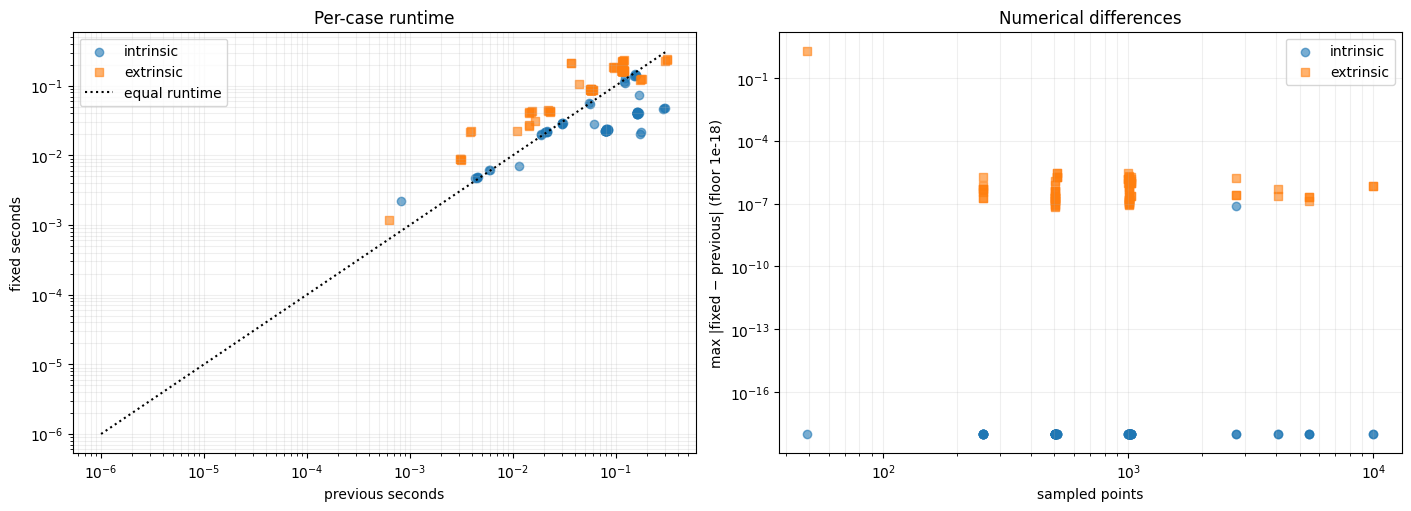

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for method, marker in (("intrinsic", "o"), ("extrinsic", "s")):
    rows = report[(report.method == method) & (report.previous_status == "ok") & (report.fixed_status == "ok")]
    axes[0].scatter(rows.previous_seconds, rows.fixed_seconds, marker=marker, alpha=.6, label=method)
    axes[1].scatter(rows.points, rows.max_abs_difference.clip(lower=1e-18), marker=marker, alpha=.6, label=method)
limit = max(report.previous_seconds.max(), report.fixed_seconds.max())
axes[0].plot([1e-6, limit], [1e-6, limit], "k:", label="equal runtime")
axes[0].set(xscale="log", yscale="log", xlabel="previous seconds", ylabel="fixed seconds", title="Per-case runtime")
axes[1].set(xscale="log", yscale="log", xlabel="sampled points", ylabel="max |fixed − previous| (floor 1e-18)", title="Numerical differences")
for ax in axes:
    ax.grid(True, which="both", alpha=.2); ax.legend()
plt.show()


In [26]:
# Copy the printed text into a Markdown cell to retain this run's report.
def build_run_markdown(rows, run_metadata, generated_at=None):
    """Describe recorded rows only; pair successful timings before summing."""
    generated_at = generated_at or datetime.now(ZoneInfo(run_metadata.get("report_timezone", "Europe/Berlin")))
    timestamp = generated_at.isoformat(timespec="seconds") if isinstance(generated_at, datetime) else str(generated_at)
    frame = pd.DataFrame(rows).copy()
    for column in ("family", "case", "method", "previous_status", "fixed_status"):
        if column not in frame:
            frame[column] = pd.Series(index=frame.index, dtype="object")
    ordinary = frame[frame.family != "review"].copy()
    review = frame[frame.family == "review"].copy()

    def number(value, precision=".3g"):
        try:
            return format(float(value), precision) if np.isfinite(float(value)) else "n/a"
        except (TypeError, ValueError):
            return "n/a"

    def table_text(value):
        return str(value).replace("|", "\\|").replace("\n", " ")

    def numeric(data, column):
        return pd.to_numeric(data.get(column, pd.Series(np.nan, index=data.index)), errors="coerce")

    def observed(column):
        if column not in frame or frame.empty:
            return "none recorded"
        return ", ".join(sorted({str(value) for value in frame[column].dropna()}))

    configuration = run_metadata.get("configuration", {})
    baselines = run_metadata.get("previous_commits", {})
    hashes = run_metadata.get("previous_hashes", {})
    original_hash = hashes.get("intrinsic", {}).get("microscope.computations_grid.curvature", "not recorded")
    profile = run_metadata.get("profile", "not recorded")
    lines = [f"## Recorded {profile} execution — {timestamp}", "",
        f"Run `{run_metadata.get('run_id', 'not recorded')}`; started `{run_metadata.get('started_at', 'not recorded')}`. "
        f"This report contains {len(ordinary)} ordinary comparison rows and {len(review)} review-probe rows currently recorded. "
        "Unexecuted cases are not counted as successes.", "",
        f"Configured device: `{run_metadata.get('device', 'not recorded')}` "
        f"({run_metadata.get('device_name', 'hardware not recorded')}); observed row devices: `{observed('device')}`. "
        f"Configured dtype: `{run_metadata.get('dtype', 'not recorded')}`; observed input dtypes: `{observed('dtype')}`. "
        f"Seed: `{run_metadata.get('seed', 'not recorded')}`; CPU threads: `{run_metadata.get('cpu_threads', 'not recorded')}`.", "",
        f"Intrinsic baseline: original attachment / `{baselines.get('intrinsic', 'not recorded')}`, "
        f"SHA-256 `{original_hash}`. Extrinsic baseline: pre-fix `{baselines.get('extrinsic', 'not recorded')}`. "
        f"Current checkout: `{run_metadata.get('current_commit', 'not recorded')}`; "
        f"dirty working tree: {'yes' if run_metadata.get('dirty') else 'no'}. "
        "Exact source hashes and snapshots are retained in the run directory.", "",
        "| Family | Method | Comparisons | Paired OK | Maximum absolute difference | Previous seconds | Current seconds | Previous / current |",
        "| --- | --- | ---: | ---: | ---: | ---: | ---: | ---: |",
    ]
    if ordinary.empty:
        lines.append("| No ordinary results recorded | — | 0 | 0 | n/a | n/a | n/a | n/a |")
    else:
        ordinary["report_family"] = ordinary.family.replace({"2D": "mathematical", "slow": "mathematical", "graphs": "mathematical"})
        for (family, method), group in ordinary.groupby(["report_family", "method"], sort=True):
            paired = group[(group.previous_status == "ok") & (group.fixed_status == "ok")]
            previous_times = numeric(paired, "previous_seconds")
            current_times = numeric(paired, "fixed_seconds")
            timed = np.isfinite(previous_times) & np.isfinite(current_times) & (previous_times > 0) & (current_times > 0)
            previous_sum = previous_times[timed].sum() if timed.any() else np.nan
            current_sum = current_times[timed].sum() if timed.any() else np.nan
            maximum = numeric(paired, "max_abs_difference").max()
            speedup = previous_sum/current_sum if timed.any() else np.nan
            speedup_text = number(speedup, ".2f") + "×" if np.isfinite(speedup) else "n/a"
            lines.append(f"| {table_text(family)} | {table_text(method)} | {len(group)} | {len(paired)} | "
                         f"{number(maximum)} | {number(previous_sum, '.3f')} | {number(current_sum, '.3f')} | {speedup_text} |")
    lines += ["",
        f"Times sum per-case medians of {run_metadata.get('repeats', 'unrecorded')} timed calls after "
        f"{run_metadata.get('warmup_calls', 'unrecorded')} untimed warm-up call(s). Only matching rows where both versions "
        "succeeded and have finite positive timings contribute to runtime totals. Preparation, hashing and comparisons "
        "are excluded; CUDA timings are synchronized. Values above 1× favor current code. Review probes are excluded from this table.", "",
    ]
    if not ordinary.empty:
        previous_ok = ordinary.previous_status == "ok"
        current_ok = ordinary.fixed_status == "ok"
        paired = ordinary[previous_ok & current_ok]
        maximum = numeric(paired, "max_abs_difference").max()
        if (previous_ok & current_ok).all():
            lines.append(f"All {len(ordinary)} recorded ordinary comparisons completed under both versions. "
                         f"Their maximum reported pointwise change was {number(maximum)}.")
        else:
            lines.append(f"Ordinary results: previous succeeded in {int(previous_ok.sum())}/{len(ordinary)} rows; "
                         f"current succeeded in {int(current_ok.sum())}/{len(ordinary)}. "
                         f"Previous failure/current success: {int((~previous_ok & current_ok).sum())}; "
                         f"previous success/current failure: {int((previous_ok & ~current_ok).sum())}; "
                         f"neither succeeded: {int((~previous_ok & ~current_ok).sum())}. "
                         f"Maximum reported change among paired successes: {number(maximum)}.")
        if "bitwise_equal" in paired:
            measured = paired.bitwise_equal.dropna()
            lines.append(f"Bitwise equality: {int(measured.astype(bool).sum())}/{len(measured)} paired rows with an equality result.")
        lines.append("")

    for family in ("dsprites", "coil20"):
        images = ordinary[ordinary.family == family]
        if images.empty:
            continue
        shapes = sorted({tuple(shape) for shape in images["shape"]})
        features = sorted({int(value) for value in numeric(images, "features").dropna()})
        patches = sorted({tuple(value) for value in images["patches"]})
        lines += [f"`{family}`: {images['case'].nunique()} recorded classes; input grids `{shapes}`; "
                  f"feature counts `{features}`; patch sizes `{patches}`.", ""]

    if not review.empty:
        lines += ["Review probes (intentional fixes and validation behavior):", "",
            "| Probe | Method | Previous status | Current status | Previous mean | Current mean | Max absolute change |",
            "| --- | --- | --- | --- | ---: | ---: | ---: |"]
        for _, row in review.iterrows():
            lines.append(f"| {table_text(row['case'])} | {table_text(row['method'])} | "
                         f"{table_text(row['previous_status'])} | {table_text(row['fixed_status'])} | "
                         f"{number(row.get('previous_mean'))} | {number(row.get('fixed_mean'))} | {number(row.get('max_abs_difference'))} |")
        lines.append("")

    failures = frame[(frame.previous_status != "ok") | (frame.fixed_status != "ok")]
    if not failures.empty:
        lines += ["Recorded failures/nonfinite results:", "",
                  "| Case | Method | Previous | Current |", "| --- | --- | --- | --- |"]
        for _, row in failures.iterrows():
            descriptions = []
            for version in ("previous", "fixed"):
                error = row.get(version + "_error")
                error = error if isinstance(error, str) else ""
                descriptions.append(str(row[version + "_status"]) + (": " + error if error else ""))
            lines.append(f"| {table_text(row['case'])} | {table_text(row['method'])} | "
                         f"{table_text(descriptions[0])} | {table_text(descriptions[1])} |")
        lines.append("")

    lines += [
        f"Configuration: random isometry `{configuration.get('apply_random_isometry', 'not recorded')}`; "
        f"total-test families `{configuration.get('include_total_test_grid', 'not recorded')}`; "
        f"slow tests `{configuration.get('include_slow_tests', 'not recorded')}`; "
        f"selected slow cases `{configuration.get('slow_case_names', 'not recorded')}`; "
        f"full dSprites run `{configuration.get('include_full_dsprites', 'not recorded')}`; "
        f"original-profile size count `{configuration.get('n_sizes', 'not recorded')}`.", "",
        f"Environment: Python `{run_metadata.get('python', 'not recorded').splitlines()[0]}`; "
        f"Torch `{run_metadata.get('torch', 'not recorded')}`; NumPy `{run_metadata.get('numpy', 'not recorded')}`; "
        f"CUDA build `{run_metadata.get('cuda_build', 'not recorded')}`; platform `{run_metadata.get('platform', 'not recorded')}`.", "",
    ]
    if profile == "bounded":
        lines += ["This bounded profile checks the recorded cases at reduced resolutions. It does not establish "
                  "original-maximum-grid agreement or converged image geometry.", ""]
    lines += [f"Machine-readable values/times/errors are in `results.csv` and `results.json` under "
              f"`{run_metadata.get('output_dir', 'not recorded')}`. Pointwise NPZ files are retained where configured. "
              "`environment.json`, the source patch and frozen/current source snapshots identify this execution."]
    return "\n".join(lines) + "\n"


generated_report_markdown = build_run_markdown(all_results, metadata)
(OUTPUT_DIR / "run-report.md").write_text(generated_report_markdown)
print(generated_report_markdown)


## Recorded bounded execution — 2026-10-27T10:49:09+01:00

Run `20261027T104713_115615+0100`; started `2026-10-27T10:47:13+01:00`. This report contains 152 ordinary comparison rows and 12 review-probe rows currently recorded. Unexecuted cases are not counted as successes.

Configured device: `cuda:0` (NVIDIA GeForce RTX 4090); observed row devices: `cuda:0`. Configured dtype: `float32`; observed input dtypes: `float32, float64, int64`. Seed: `0`; CPU threads: `2`.

Intrinsic baseline: original attachment / `eb2e8842cde4b10285b6edac7b6b99d272196e74`, SHA-256 `241a883882d17cab3cc135445c496940de4eb6082086ebd609409a65dc8ae840`. Extrinsic baseline: pre-fix `99cf6c9e7186e422c132720de2b1294a247423ed`. Current checkout: `44fdbdd4c1b0774a00aee3bba39052fee1d1e3f3`; dirty working tree: yes. Exact source hashes and snapshots are retained in the run directory.

| Family | Method | Comparisons | Paired OK | Maximum absolute difference | Previous seconds | Current seconds | Previous / current |
| ---

The current implementation validates inputs and patch extents, diagnoses numerical tangent rank, and stabilizes the extrinsic Gauss contraction. Intrinsic curvature uses conditioned direct inversion with QR fallback and metric-first tiling. True rank loss remains an error without regularization.

The generated report describes only the result rows currently available, including failures. Copy its plain-text output into a Markdown cell to retain a readable record of this execution. Source snapshots and machine-readable results under the unique `OUTPUT_DIR` identify the exact baselines, working code, configuration and device. Reduced CPU checks do not establish full-grid or GPU behavior.


## Historical bounded CPU execution — 2026-10-26

This historical record compares pre-fix `99cf6c9` against the seven-fix implementation **before** conditioning/metric-first speedups. It does not describe the newly configured original-attachment/current comparison. Generate a fresh report above for new results.

Executed all 15 mathematical cases/ambient variants and all 23 image classes at two bounded resolutions, for both curvature methods. The additional six review probes document intentional fixes and validation errors. No original-profile maximum-grid or GPU execution is claimed.

| Family | Method | Comparisons | Maximum absolute difference | Previous seconds | Fixed seconds | Previous / fixed |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| coil20 | extrinsic | 40 | 2.38e-14 | 88.498 | 48.143 | 1.84× |
| coil20 | intrinsic | 40 | 1.01e-15 | 25.256 | 24.919 | 1.01× |
| dsprites | extrinsic | 6 | 8.24e-15 | 67.946 | 36.548 | 1.86× |
| dsprites | intrinsic | 6 | 6.38e-16 | 33.683 | 22.957 | 1.47× |
| mathematical | extrinsic | 30 | 1.24e-14 | 2.147 | 2.735 | 0.79× |
| mathematical | intrinsic | 30 | 8.88e-15 | 1.679 | 2.420 | 0.69× |

Times are sums of per-case medians (two timed repetitions after warm-up); they exclude image preparation and comparisons. Values above 1× favor the fixed implementation. QR/rank validation adds overhead on small mathematical cases; partial-patch corrections reduce work in these bounded image cases. These timings do not predict performance on the full original grids.

The ordinary cases all completed under both versions. Their maximum pointwise change was 2.38e-14. The review probes separately recover the artificial-padding, narrow-plane and reversed-stride failures, reject malformed spacing/integer input, and correct the extrinsic anisotropic-graph curvature from 0 to 2.

The dSprites bounded renderer used seven sizes, sixteen rotations and seven translations per direction (translation coordinates −7,−5,…,5). COIL used eighteen original views, seven sizes and eight in-plane rotations. Each image keeps all 4096 pixels. Nonperiodic cropping leaves few retained coordinates in these small runs, so agreement here is not convergence evidence.

Historical per-case values/times/errors are under `outputs/CURVATURE_FIXES_20261026/bounded/` in `results.csv` and `results.json`; pointwise arrays are in the referenced NPZ files. The environment, input PNG hashes and exact numerical source snapshots are retained there.

## Recorded bounded execution — 2026-10-27T10:49:09+01:00

Run `20261027T104713_115615+0100`; started `2026-10-27T10:47:13+01:00`. This report contains 152 ordinary comparison rows and 12 review-probe rows currently recorded. Unexecuted cases are not counted as successes.

Configured device: `cuda:0` (NVIDIA GeForce RTX 4090); observed row devices: `cuda:0`. Configured dtype: `float32`; observed input dtypes: `float32, float64, int64`. Seed: `0`; CPU threads: `2`.

Intrinsic baseline: original attachment / `eb2e8842cde4b10285b6edac7b6b99d272196e74`, SHA-256 `241a883882d17cab3cc135445c496940de4eb6082086ebd609409a65dc8ae840`. Extrinsic baseline: pre-fix `99cf6c9e7186e422c132720de2b1294a247423ed`. Current checkout: `44fdbdd4c1b0774a00aee3bba39052fee1d1e3f3`; dirty working tree: yes. Exact source hashes and snapshots are retained in the run directory.

| Family | Method | Comparisons | Paired OK | Maximum absolute difference | Previous seconds | Current seconds | Previous / current |
| --- | --- | ---: | ---: | ---: | ---: | ---: | ---: |
| coil20 | extrinsic | 40 | 40 | 2.14e-06 | 3.504 | 4.997 | 0.70× |
| coil20 | intrinsic | 40 | 40 | 0 | 4.875 | 1.266 | 3.85× |
| dsprites | extrinsic | 6 | 6 | 1.77e-06 | 1.465 | 1.077 | 1.36× |
| dsprites | intrinsic | 6 | 6 | 7.68e-08 | 1.405 | 0.258 | 5.44× |
| mathematical | extrinsic | 30 | 30 | 2.86e-06 | 1.243 | 2.779 | 0.45× |
| mathematical | intrinsic | 30 | 30 | 0 | 1.651 | 1.532 | 1.08× |

Times sum per-case medians of 2 timed calls after 1 untimed warm-up call(s). Only matching rows where both versions succeeded and have finite positive timings contribute to runtime totals. Preparation, hashing and comparisons are excluded; CUDA timings are synchronized. Values above 1× favor current code. Review probes are excluded from this table.

All 152 recorded ordinary comparisons completed under both versions. Their maximum reported pointwise change was 2.86e-06.
Bitwise equality: 75/152 paired rows with an equality result.

`dsprites`: 3 recorded classes; input grids `[(7, 8, 7, 7), (7, 16, 7, 7)]`; feature counts `[4096]`; patch sizes `[(8, 8, 8, 8)]`.

`coil20`: 20 recorded classes; input grids `[(9, 7, 8), (18, 7, 8)]`; feature counts `[4096]`; patch sizes `[(8, 8, 8)]`.

Review probes (intentional fixes and validation behavior):

| Probe | Method | Previous status | Current status | Previous mean | Current mean | Max absolute change |
| --- | --- | --- | --- | ---: | ---: | ---: |
| padding cylinder | intrinsic | error | ok | n/a | 0 | n/a |
| padding cylinder | extrinsic | error | ok | n/a | -1.39e-17 | n/a |
| Gauss cancellation | intrinsic | ok | ok | 2.13 | 2.13 | 0 |
| Gauss cancellation | extrinsic | ok | ok | 0 | 2 | 2 |
| full rank narrow plane | intrinsic | error | ok | n/a | 0 | n/a |
| full rank narrow plane | extrinsic | error | ok | n/a | 0 | n/a |
| missing spacing | intrinsic | ok | error | 0 | n/a | n/a |
| missing spacing | extrinsic | error | error | n/a | n/a | n/a |
| integer input | intrinsic | ok | error | 0.000577 | n/a | n/a |
| integer input | extrinsic | ok | error | 0 | n/a | n/a |
| reversed grid | intrinsic | error | ok | n/a | 0.000577 | n/a |
| reversed grid | extrinsic | error | ok | n/a | 0.000577 | n/a |

Recorded failures/nonfinite results:

| Case | Method | Previous | Current |
| --- | --- | --- | --- |
| padding cylinder | intrinsic | error: _LinAlgError: linalg.inv: (Batch element 35): The diagonal element 2 is zero, the inversion could not be completed because the input matrix is singular. | ok |
| padding cylinder | extrinsic | error: _LinAlgError: torch.linalg.solve: (Batch element 20): The solver failed because the input matrix is singular. | ok |
| full rank narrow plane | intrinsic | error: _LinAlgError: linalg.inv: (Batch element 0): The diagonal element 2 is zero, the inversion could not be completed because the input matrix is singular. | ok |
| full rank narrow plane | extrinsic | error: _LinAlgError: torch.linalg.solve: (Batch element 0): The solver failed because the input matrix is singular. | ok |
| missing spacing | intrinsic | ok | error: ValueError: Expected 2 difference intervals, one spacing per grid axis. |
| missing spacing | extrinsic | error: RuntimeError: unflatten: Provided sizes [2, 2] don't multiply up to the size of dim 3 (1) in the input tensor | error: ValueError: Expected 2 difference intervals, one spacing per grid axis. |
| integer input | intrinsic | ok | error: TypeError: Curvature requires float32 or float64 inputs. |
| integer input | extrinsic | ok | error: TypeError: Curvature requires float32 or float64 inputs. |
| reversed grid | intrinsic | error: ValueError: At least one stride in the given numpy array is negative, and tensors with negative strides are not currently supported. (You can probably work around this by making a copy of your array  with array.copy().)  | ok |
| reversed grid | extrinsic | error: ValueError: At least one stride in the given numpy array is negative, and tensors with negative strides are not currently supported. (You can probably work around this by making a copy of your array  with array.copy().)  | ok |

Configuration: random isometry `False`; total-test families `True`; slow tests `True`; selected slow cases `None`; full dSprites run `True`; original-profile size count `10`.

Environment: Python `3.10.9 (main, Feb 20 2024, 11:34:07) [GCC 11.4.0]`; Torch `2.4.1+cu118`; NumPy `1.26.3`; CUDA build `11.8`; platform `Linux-6.8.0-147-generic-x86_64-with-glibc2.39`.

This bounded profile checks the recorded cases at reduced resolutions. It does not establish original-maximum-grid agreement or converged image geometry.

Machine-readable values/times/errors are in `results.csv` and `results.json` under `/home/marios/chatgpt-projects/manifold-microscope-coding-extension/outputs/CURVATURE_REVIEW/20261027T104713_115615+0100/bounded`. Pointwise NPZ files are retained where configured. `environment.json`, the source patch and frozen/current source snapshots identify this execution.